In [25]:

from pathlib import Path

# Find the project root from the current notebook directory.
cwd = Path.cwd()
candidates = [cwd, *cwd.parents]

PROJECT_ROOT = next(
    (
        p for p in candidates
        if (p / "data").exists()
        and (p / "notebooks").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    PROJECT_ROOT = Path(
        "/Users/vs/Sem 5/Respiratory-Disease-Classification"
    )

print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())

print("\n--- Relevant existing files ---")

search_roots = [
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "reports",
]

terms = [
    "disease_sound_percent",
    "cycle",
    "annotation",
    "manifest",
    "split",
    "icbhi",
]

seen = set()

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        if any(term in path.name.lower() for term in terms):
            resolved = str(path)
            if resolved not in seen:
                seen.add(resolved)
                print(path.relative_to(PROJECT_ROOT))


Project root: /Users/vs/Sem 5/Respiratory-Disease-Classification
Project root exists: True

--- Relevant existing files ---
data/processed/cycles_clean.csv
data/processed/processed_cycles.csv
data/processed/eda/disease_sound_percent.csv
data/processed/features/respiratory_cycle_features.csv
data/processed/deep_learning/test_manifest.csv
data/processed/deep_learning/deep_learning_manifest.csv
data/processed/deep_learning/train_manifest.csv
data/processed/deep_learning/cnn_baseline/test_cnn_manifest.csv
data/processed/deep_learning/cnn_baseline/validation_cnn_manifest.csv
data/processed/deep_learning/cnn_baseline/cnn_split_summary.csv
data/processed/deep_learning/cnn_baseline/train_cnn_manifest.csv
data/processed/deep_learning/cnn_baseline/cnn_patient_disjoint_manifest.csv
data/processed/features/.ipynb_checkpoints/respiratory_cycle_features-checkpoint.csv
data/processed/eda/.ipynb_checkpoints/disease_sound_percent-checkpoint.csv
data/interim/cycles.csv
data/interim/cycles_validation.csv

In [26]:

import pandas as pd
from pathlib import Path

files_to_check = {
    "clean_cycles": PROJECT_ROOT / "data/processed/cycles_clean.csv",
    "processed_cycles": PROJECT_ROOT / "data/processed/processed_cycles.csv",
    "cycle_features": PROJECT_ROOT / "data/processed/features/respiratory_cycle_features.csv",
    "interim_cycles": PROJECT_ROOT / "data/interim/cycles.csv",
    "official_split": PROJECT_ROOT / "data/raw/ICBHI/metadata/official_split.csv",
    "deep_learning_manifest": PROJECT_ROOT / "data/processed/deep_learning/deep_learning_manifest.csv",
}

for name, path in files_to_check.items():
    print("\n" + "=" * 75)
    print(f"{name}: {path.name}")
    print("Exists:", path.exists())

    if not path.exists():
        continue

    try:
        df = pd.read_csv(path, nrows=5)
        print("Columns:", df.columns.tolist())
        print("Sample rows:")
        display(df.head(3))
    except Exception as e:
        print("Could not read file:", repr(e))



clean_cycles: cycles_clean.csv
Exists: True
Columns: ['patient_id', 'recording_id', 'chest_location', 'acquisition_mode', 'equipment', 'wav_path', 'cycle_number', 'start_time', 'end_time', 'crackles', 'wheezes', 'sound_label']
Sample rows:


,patient_id,recording_id,chest_location,acquisition_mode,equipment,wav_path,cycle_number,start_time,end_time,crackles,wheezes,sound_label
0,101,1b1,Al,sc,Meditron,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,1,0.036,0.579,0,0,Normal
1,101,1b1,Al,sc,Meditron,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,2,0.579,2.450,0,0,Normal
2,101,1b1,Al,sc,Meditron,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,3,2.450,3.893,0,0,Normal



processed_cycles: processed_cycles.csv
Exists: True
Columns: ['patient_id', 'diagnosis', 'recording_id', 'chest_location', 'acquisition_mode', 'equipment', 'cycle_number', 'sound_label', 'crackles', 'wheezes', 'start_time', 'end_time', 'original_sample_rate', 'target_sample_rate', 'original_samples', 'processed_samples', 'original_duration', 'processed_duration', 'original_peak', 'original_rms', 'normalized_peak', 'processed_path', 'processing_status']
Sample rows:


,patient_id,diagnosis,recording_id,chest_location,acquisition_mode,equipment,cycle_number,sound_label,crackles,wheezes,...,target_sample_rate,original_samples,processed_samples,original_duration,processed_duration,original_peak,original_rms,normalized_peak,processed_path,processing_status
0,101,URTI,1b1,Al,sc,Meditron,1,Normal,0,0,...,4000,23946,2172,0.542993,0.543,0.357483,0.079829,1.0,audio/cycles/101/1b1_Al_001.wav,success
1,101,URTI,1b1,Al,sc,Meditron,2,Normal,0,0,...,4000,82511,7484,1.870998,1.871,0.394714,0.073536,1.0,audio/cycles/101/1b1_Al_002.wav,success
2,101,URTI,1b1,Al,sc,Meditron,3,Normal,0,0,...,4000,63636,5772,1.442993,1.443,0.411743,0.070142,1.0,audio/cycles/101/1b1_Al_003.wav,success



cycle_features: respiratory_cycle_features.csv
Exists: True
Columns: ['patient_id', 'recording_id', 'chest_location', 'acquisition_mode', 'equipment', 'cycle_number', 'start_time', 'end_time', 'sound_label', 'crackles', 'wheezes', 'diagnosis', 'processed_path', 'mean', 'std', 'variance', 'rms', 'max', 'min', 'peak_to_peak', 'median', 'skewness', 'kurtosis', 'energy', 'zero_crossing_rate', 'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff', 'spectral_flatness', 'spectral_energy', 'dominant_frequency', 'spectral_entropy', 'band_energy_0_500', 'band_energy_500_1000', 'band_energy_1000_1500', 'band_energy_1500_2000', 'mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'wavelet_energy', 'wavelet_entropy', 'wavelet_std']
Sample rows:


...

,patient_id,recording_id,chest_location,acquisition_mode,equipment,wav_path,cycle_number,start_time,end_time,crackles,wheezes,sound_label
0,101,1b1,Al,sc,Meditron,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,1,0.036,0.579,0,0,Normal
1,101,1b1,Al,sc,Meditron,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,2,0.579,2.450,0,0,Normal
2,101,1b1,Al,sc,Meditron,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,3,2.450,3.893,0,0,Normal



official_split: official_split.csv
Exists: True
Columns: ['recording_id', 'split']
Sample rows:


,recording_id,split
0,101_1b1_Al_sc_Meditron,test
1,101_1b1_Pr_sc_Meditron,test
2,102_1b1_Ar_sc_Meditron,test



deep_learning_manifest: deep_learning_manifest.csv
Exists: True
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path']
Sample rows:


,patient_id,recording_id,chest_location,diagnosis,disease_label,official_split,audio_path
0,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...
1,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...
2,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...


In [27]:

import pandas as pd
import numpy as np

# Load the existing cycle-level feature table.
features_path = (
    PROJECT_ROOT
    / "data/processed/features/respiratory_cycle_features.csv"
)

sound_df = pd.read_csv(features_path)

# Normalize the binary sound annotations.
sound_df["crackles"] = pd.to_numeric(
    sound_df["crackles"], errors="coerce"
)
sound_df["wheezes"] = pd.to_numeric(
    sound_df["wheezes"], errors="coerce"
)

print("=" * 70)
print("1. DATASET OVERVIEW")
print("=" * 70)
print("Rows:", len(sound_df))
print("Unique patients:", sound_df["patient_id"].nunique())
print("Missing crackle labels:", sound_df["crackles"].isna().sum())
print("Missing wheeze labels:", sound_df["wheezes"].isna().sum())

# Keep only rows with valid binary annotations.
valid_mask = (
    sound_df["crackles"].isin([0, 1])
    & sound_df["wheezes"].isin([0, 1])
)

sound_df = sound_df.loc[valid_mask].copy()

# Derive four mutually exclusive classes from the annotations.
conditions = [
    (sound_df["crackles"] == 0) & (sound_df["wheezes"] == 0),
    (sound_df["crackles"] == 1) & (sound_df["wheezes"] == 0),
    (sound_df["crackles"] == 0) & (sound_df["wheezes"] == 1),
    (sound_df["crackles"] == 1) & (sound_df["wheezes"] == 1),
]

labels = [
    "Normal",
    "Crackles",
    "Wheezes",
    "Both",
]

sound_df["phenotype"] = np.select(
    conditions,
    labels,
    default="Invalid"
)

print("\n" + "=" * 70)
print("2. FOUR-CLASS DISTRIBUTION")
print("=" * 70)

print(sound_df["phenotype"].value_counts().reindex(labels, fill_value=0))

print("\nPercentages:")
print(
    (sound_df["phenotype"].value_counts(normalize=True)
     .reindex(labels, fill_value=0) * 100).round(2)
)

print("\n" + "=" * 70)
print("3. EXISTING SOUND LABEL CONSISTENCY")
print("=" * 70)

if "sound_label" in sound_df.columns:
    print(pd.crosstab(
        sound_df["sound_label"],
        sound_df["phenotype"],
        dropna=False
    ))
else:
    print("No sound_label column found.")

print("\n" + "=" * 70)
print("4. PATIENT-LEVEL CLASS COVERAGE")
print("=" * 70)

patient_class_counts = pd.crosstab(
    sound_df["patient_id"],
    sound_df["phenotype"]
)

print("Patients represented in each class:")
print((patient_class_counts > 0).sum().reindex(labels, fill_value=0))

print("\nCycles per patient — summary:")
print(sound_df.groupby("patient_id").size().describe())


1. DATASET OVERVIEW
Rows: 6898
Unique patients: 126
Missing crackle labels: 0
Missing wheeze labels: 0

2. FOUR-CLASS DISTRIBUTION
phenotype
Normal      3642
Crackles    1864
Wheezes      886
Both         506
Name: count, dtype: int64

Percentages:
phenotype
Normal      52.80
Crackles    27.02
Wheezes     12.84
Both         7.34
Name: proportion, dtype: float64

3. EXISTING SOUND LABEL CONSISTENCY
phenotype    Both  Crackles  Normal  Wheezes
sound_label                                 
Both          506         0       0        0
Crackles        0      1864       0        0
Normal          0         0    3642        0
Wheezes         0         0       0      886

4. PATIENT-LEVEL CLASS COVERAGE
Patients represented in each class:
phenotype
Normal      124
Crackles     74
Wheezes      63
Both         35
dtype: int64

Cycles per patient — summary:
count    126.000000
mean      54.746032
std       67.686328
min        4.000000
25%       11.000000
50%       26.500000
75%       74.000000
ma

In [28]:

import pandas as pd
from pathlib import Path

split_path = (
    PROJECT_ROOT / "data/raw/ICBHI/metadata/official_split.csv"
)

split_df = pd.read_csv(split_path)

print("Official split columns:", split_df.columns.tolist())
print("\nOfficial split distribution:")
print(split_df["split"].value_counts(dropna=False))

# Build the ICBHI recording key used by the official split.
# The metadata's recording_id is typically like "1b1";
# the official key includes patient and recording details.
sound_df["recording_key"] = (
    sound_df["patient_id"].astype(str)
    + "_"
    + sound_df["recording_id"].astype(str)
    + "_"
    + sound_df["chest_location"].astype(str)
    + "_"
    + sound_df["acquisition_mode"].astype(str)
    + "_"
    + sound_df["equipment"].astype(str)
)

print("\nExample cycle recording keys:")
print(sound_df["recording_key"].head().to_list())

print("\nExample official recording keys:")
print(split_df["recording_id"].head().to_list())

# Join the official split onto each cycle.
sound_df = sound_df.merge(
    split_df.rename(columns={"recording_id": "recording_key"}),
    on="recording_key",
    how="left",
    validate="many_to_one"
)

print("\n" + "=" * 70)
print("OFFICIAL SPLIT MATCHING")
print("=" * 70)
print("Total cycles:", len(sound_df))
print("Matched cycles:", sound_df["split"].notna().sum())
print("Unmatched cycles:", sound_df["split"].isna().sum())

print("\nCycles per split:")
print(sound_df["split"].value_counts(dropna=False))

print("\nFour-class counts per split:")
print(pd.crosstab(
    sound_df["split"],
    sound_df["phenotype"],
    margins=True
))

# Patient overlap between official train and test recordings.
patient_sets = {
    split: set(group["patient_id"].astype(str))
    for split, group in sound_df.dropna(subset=["split"]).groupby("split")
}

print("\n" + "=" * 70)
print("PATIENT OVERLAP AUDIT")
print("=" * 70)

for split, patients in patient_sets.items():
    print(f"{split}: {len(patients)} unique patients")

if "train" in patient_sets and "test" in patient_sets:
    overlap = patient_sets["train"] & patient_sets["test"]
    print("Train-test shared patients:", len(overlap))
    if overlap:
        print("Example overlapping patient IDs:", sorted(overlap)[:20])

if "validation" in patient_sets:
    if "train" in patient_sets:
        print(
            "Train-validation shared patients:",
            len(patient_sets["train"] & patient_sets["validation"])
        )
    if "test" in patient_sets:
        print(
            "Validation-test shared patients:",
            len(patient_sets["validation"] & patient_sets["test"])
        )


Official split columns: ['recording_id', 'split']

Official split distribution:
split
train    539
test     381
Name: count, dtype: int64

Example cycle recording keys:
['101_1b1_Al_sc_Meditron', '101_1b1_Al_sc_Meditron', '101_1b1_Al_sc_Meditron', '101_1b1_Al_sc_Meditron', '101_1b1_Al_sc_Meditron']

Example official recording keys:
['101_1b1_Al_sc_Meditron', '101_1b1_Pr_sc_Meditron', '102_1b1_Ar_sc_Meditron', '103_2b2_Ar_mc_LittC2SE', '104_1b1_Al_sc_Litt3200']

OFFICIAL SPLIT MATCHING
Total cycles: 6898
Matched cycles: 6887
Unmatched cycles: 11

Cycles per split:
split
train    4131
test     2756
NaN        11
Name: count, dtype: int64

Four-class counts per split:
phenotype  Both  Crackles  Normal  Wheezes   All
split                                           
test        143       649    1579      385  2756
train       363      1210    2057      501  4131
All         506      1859    3636      886  6887

PATIENT OVERLAP AUDIT
test: 49 unique patients
train: 79 unique patients
Train-t

In [29]:

import pandas as pd
from pathlib import Path

manifest_paths = {
    "deep_learning": PROJECT_ROOT / "data/processed/deep_learning/deep_learning_manifest.csv",
    "train": PROJECT_ROOT / "data/processed/deep_learning/train_manifest.csv",
    "test": PROJECT_ROOT / "data/processed/deep_learning/test_manifest.csv",
    "cnn_train": PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline/train_cnn_manifest.csv",
    "cnn_validation": PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline/validation_cnn_manifest.csv",
    "cnn_test": PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline/test_cnn_manifest.csv",
    "cnn_patient_disjoint": PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline/cnn_patient_disjoint_manifest.csv",
}

manifests = {}

for name, path in manifest_paths.items():
    print("\n" + "=" * 70)
    print(name, "| Exists:", path.exists())

    if not path.exists():
        continue

    df = pd.read_csv(path)
    manifests[name] = df

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    if "patient_id" in df.columns:
        print("Unique patients:", df["patient_id"].nunique())

    if "official_split" in df.columns:
        print("Split distribution:")
        print(df["official_split"].value_counts(dropna=False))

# Check patient overlap for the CNN manifests.
print("\n" + "=" * 70)
print("CNN MANIFEST PATIENT OVERLAP")

for left, right in [
    ("cnn_train", "cnn_validation"),
    ("cnn_train", "cnn_test"),
    ("cnn_validation", "cnn_test"),
]:
    if left not in manifests or right not in manifests:
        continue

    a = manifests[left]
    b = manifests[right]

    if "patient_id" not in a.columns or "patient_id" not in b.columns:
        print(f"{left} vs {right}: patient_id column unavailable")
        continue

    pa = set(a["patient_id"].dropna().astype(str))
    pb = set(b["patient_id"].dropna().astype(str))

    print(f"{left} vs {right}: {len(pa & pb)} shared patients")



deep_learning | Exists: True
Rows: 6898
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path']
Unique patients: 126
Split distribution:
official_split
train    4142
test     2756
Name: count, dtype: int64

train | Exists: True
Rows: 4142
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path']
Unique patients: 79
Split distribution:
official_split
train    4142
Name: count, dtype: int64

test | Exists: True
Rows: 2756
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path']
Unique patients: 49
Split distribution:
official_split
test    2756
Name: count, dtype: int64

cnn_train | Exists: True
Rows: 4423
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']
Unique patients: 82
Split distribution:
official_split
train    2

In [30]:

import pandas as pd
from pathlib import Path

manifest_dir = PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"

manifest_files = {
    "train": manifest_dir / "train_cnn_manifest.csv",
    "validation": manifest_dir / "validation_cnn_manifest.csv",
    "test": manifest_dir / "test_cnn_manifest.csv",
}

# Load the existing patient-disjoint assignments.
parts = []

for split_name, path in manifest_files.items():
    df = pd.read_csv(path)
    df["phenotype_split"] = split_name
    parts.append(df)

cnn_assignments = pd.concat(parts, ignore_index=True)

print("Combined manifest rows:", len(cnn_assignments))
print("Unique manifest patients:", cnn_assignments["patient_id"].nunique())
print("\nRows by intended CNN split:")
print(cnn_assignments["phenotype_split"].value_counts())

print("\nManifest columns:")
print(cnn_assignments.columns.tolist())

# Compare the likely cycle-audio path columns.
for col in ["audio_path", "processed_path"]:
    if col in cnn_assignments.columns:
        print(f"\n{col} examples:")
        print(cnn_assignments[col].head(5).to_list())

# Check whether the sound feature table has duplicate cycle identities.
cycle_key = [
    "patient_id", "recording_id", "chest_location", "cycle_number"
]

print("\nDuplicate cycle identities in sound table:",
      sound_df.duplicated(cycle_key).sum())

# Check manifest uniqueness at recording and patient-recording-location levels.
for key in [
    ["patient_id", "recording_id", "chest_location"],
    ["patient_id", "recording_id", "chest_location", "audio_path"],
]:
    if all(c in cnn_assignments.columns for c in key):
        print(f"\nManifest duplicate rows for key {key}:",
              cnn_assignments.duplicated(key).sum())

# Check the intended split has no patient overlap.
patient_sets = {
    name: set(df["patient_id"].astype(str))
    for name, df in cnn_assignments.groupby("phenotype_split")
}

print("\nPatient overlap:")
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    print(f"{a} vs {b}: {len(patient_sets[a] & patient_sets[b])}")


Combined manifest rows: 6898
Unique manifest patients: 126

Rows by intended CNN split:
phenotype_split
train         4423
test          1561
validation     914
Name: count, dtype: int64

Manifest columns:
['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split', 'phenotype_split']

audio_path examples:
['/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/audio/cycles/102/1b1_Ar_001.wav', '/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/audio/cycles/102/1b1_Ar_002.wav', '/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/audio/cycles/102/1b1_Ar_003.wav', '/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/audio/cycles/102/1b1_Ar_004.wav', '/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/audio/cycles/102/1b1_Ar_005.wav']

Duplicate cycle identities in sound table: 0

Manifest duplicate rows for key ['patient_id', 'recording_id', 'chest_locati

In [31]:

import pandas as pd
from pathlib import Path

# Reload clean data to avoid state left by the failed merge.
features_path = (
    PROJECT_ROOT / "data/processed/features/respiratory_cycle_features.csv"
)
sound_df = pd.read_csv(features_path)

manifest_dir = PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"

manifest_parts = []
for split_name, filename in [
    ("train", "train_cnn_manifest.csv"),
    ("validation", "validation_cnn_manifest.csv"),
    ("test", "test_cnn_manifest.csv"),
]:
    part = pd.read_csv(manifest_dir / filename)
    part["phenotype_split"] = split_name
    manifest_parts.append(part)

cnn_assignments = pd.concat(manifest_parts, ignore_index=True)

# Normalize key columns to comparable types.
for df in [sound_df, cnn_assignments]:
    df["patient_key"] = df["patient_id"].astype(str).str.strip()
    df["recording_key"] = df["recording_id"].astype(str).str.strip()
    df["location_key"] = df["chest_location"].astype(str).str.strip()

sound_df["cycle_number"] = pd.to_numeric(
    sound_df["cycle_number"], errors="coerce"
)
cnn_assignments["audio_path"] = cnn_assignments["audio_path"].astype(str)

# Derive cycle number from the manifest's audio filename.
# Example: .../1b1_Ar_001.wav -> cycle_number 1
cnn_assignments["cycle_number"] = pd.to_numeric(
    cnn_assignments["audio_path"].map(
        lambda p: Path(p).stem.rsplit("_", 1)[-1]
    ),
    errors="coerce"
)

join_keys = [
    "patient_key",
    "recording_key",
    "location_key",
    "cycle_number",
]

print("Sound rows:", len(sound_df))
print("Manifest rows:", len(cnn_assignments))
print("Duplicate sound join keys:", sound_df.duplicated(join_keys).sum())
print("Duplicate manifest join keys:", cnn_assignments.duplicated(join_keys).sum())

# Each cycle should map to one manifest split.
lookup = cnn_assignments[
    join_keys + ["phenotype_split"]
].drop_duplicates()

if lookup.duplicated(join_keys).any():
    raise ValueError(
        "Some cycle keys map to multiple splits. Inspect these rows before proceeding."
    )

sound_df = sound_df.merge(
    lookup,
    on=join_keys,
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("\nMatch audit:")
print(sound_df["_merge"].value_counts())
print("Unmatched cycles:", (sound_df["_merge"] != "both").sum())

print("\nFour-class counts by split:")
print(pd.crosstab(
    sound_df["phenotype_split"],
    sound_df["sound_label"],
    margins=True
))

print("\nUnmatched examples:")
display(
    sound_df.loc[
        sound_df["_merge"] != "both",
        ["patient_id", "recording_id", "chest_location", "cycle_number"]
    ].head(15)
)


Sound rows: 6898
Manifest rows: 6898
Duplicate sound join keys: 0
Duplicate manifest join keys: 0

Match audit:
_merge
both          6898
left_only        0
right_only       0
Name: count, dtype: int64
Unmatched cycles: 0

Four-class counts by split:
sound_label      Both  Crackles  Normal  Wheezes   All
phenotype_split                                       
test              171       462     705      223  1561
train             316      1219    2342      546  4423
validation         19       183     595      117   914
All               506      1864    3642      886  6898

Unmatched examples:


,patient_id,recording_id,chest_location,cycle_number


In [32]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

# Use the already matched sound_df.
# Exclude labels, identifiers, split metadata, and non-feature columns.
excluded_columns = {
    "patient_id", "recording_id", "chest_location",
    "acquisition_mode", "equipment", "cycle_number",
    "start_time", "end_time", "sound_label", "crackles",
    "wheezes", "diagnosis", "processed_path",
    "phenotype", "phenotype_split", "recording_key",
    "audio_filename", "patient_key", "_merge",
    "official_split", "wav_path", "processed_path",
}

# Select numeric acoustic features only.
feature_columns = [
    c for c in sound_df.select_dtypes(include=np.number).columns
    if c not in excluded_columns
]

print("Number of candidate numeric features:", len(feature_columns))
print("Features:", feature_columns)

# Explicitly select the established patient-disjoint partitions.
train_df = sound_df[sound_df["phenotype_split"] == "train"].copy()
val_df = sound_df[sound_df["phenotype_split"] == "validation"].copy()
test_df = sound_df[sound_df["phenotype_split"] == "test"].copy()

class_names = ["Normal", "Crackles", "Wheezes", "Both"]

X_train = train_df[feature_columns].replace([np.inf, -np.inf], np.nan)
y_train = train_df["sound_label"]

X_val = val_df[feature_columns].replace([np.inf, -np.inf], np.nan)
y_val = val_df["sound_label"]

X_test = test_df[feature_columns].replace([np.inf, -np.inf], np.nan)
y_test = test_df["sound_label"]

# Compute class weights from training labels only.
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(class_names),
    y=y_train,
)
class_weights = dict(zip(class_names, weights))

print("\nTraining class weights:", class_weights)

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=class_weights,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train, y_train)

# Validation is used for model selection; test remains untouched.
val_pred = rf_model.predict(X_val)

print("\n" + "=" * 65)
print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 65)
print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))
print("Macro-F1:", round(f1_score(
    y_val, val_pred, labels=class_names,
    average="macro", zero_division=0
), 4))

print("\nClassification report:")
print(classification_report(
    y_val, val_pred,
    labels=class_names,
    zero_division=0,
))

print("\nConfusion matrix (rows=true, columns=predicted):")
print(pd.DataFrame(
    confusion_matrix(y_val, val_pred, labels=class_names),
    index=class_names,
    columns=class_names,
))


Number of candidate numeric features: 39
Features: ['mean', 'std', 'variance', 'rms', 'max', 'min', 'peak_to_peak', 'median', 'skewness', 'kurtosis', 'energy', 'zero_crossing_rate', 'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff', 'spectral_flatness', 'spectral_energy', 'dominant_frequency', 'spectral_entropy', 'band_energy_0_500', 'band_energy_500_1000', 'band_energy_1000_1500', 'band_energy_1500_2000', 'mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'wavelet_energy', 'wavelet_entropy', 'wavelet_std']

Training class weights: {'Normal': np.float64(0.4721391972672929), 'Crackles': np.float64(0.9070959803117309), 'Wheezes': np.float64(2.02518315018315), 'Both': np.float64(3.4992088607594938)}

RANDOM FOREST — VALIDATION RESULTS
Accuracy: 0.5799
Balanced accuracy: 0.3446
Macro-F1: 0.3396

Classification report:
              

In [33]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
import pandas as pd
import numpy as np

extra_trees_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", ExtraTreesClassifier(
        n_estimators=400,
        class_weight=class_weights,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1,
    )),
])

extra_trees_model.fit(X_train, y_train)
et_val_pred = extra_trees_model.predict(X_val)

print("=" * 65)
print("EXTRA TREES — VALIDATION RESULTS")
print("=" * 65)

print("Accuracy:", round(accuracy_score(y_val, et_val_pred), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, et_val_pred), 4
))
print("Macro-F1:", round(f1_score(
    y_val, et_val_pred,
    labels=class_names,
    average="macro",
    zero_division=0,
), 4))

print("\nClassification report:")
print(classification_report(
    y_val, et_val_pred,
    labels=class_names,
    zero_division=0,
))

print("\nConfusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y_val, et_val_pred, labels=class_names),
    index=class_names,
    columns=class_names,
))


EXTRA TREES — VALIDATION RESULTS
Accuracy: 0.6105
Balanced accuracy: 0.315
Macro-F1: 0.3153

Classification report:
              precision    recall  f1-score   support

      Normal       0.69      0.84      0.76       595
    Crackles       0.35      0.28      0.31       183
     Wheezes       0.12      0.03      0.05       117
        Both       0.20      0.11      0.14        19

    accuracy                           0.61       914
   macro avg       0.34      0.32      0.32       914
weighted avg       0.54      0.61      0.57       914


Confusion matrix:
          Normal  Crackles  Wheezes  Both
Normal       501        68       23     3
Crackles     123        51        7     2
Wheezes       89        21        4     3
Both          13         4        0     2


In [34]:

from pathlib import Path
import pandas as pd

manifest_dir = PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"

manifest_parts = []

for split_name, filename in [
    ("train", "train_cnn_manifest.csv"),
    ("validation", "validation_cnn_manifest.csv"),
    ("test", "test_cnn_manifest.csv"),
]:
    df = pd.read_csv(manifest_dir / filename)
    df["phenotype_split"] = split_name
    manifest_parts.append(df)

cnn_assignments = pd.concat(manifest_parts, ignore_index=True)

# Verify all paths before starting audio processing.
cnn_assignments["audio_exists"] = cnn_assignments["audio_path"].map(
    lambda p: Path(str(p)).is_file()
)

print("Audio path verification")
print("=======================")
print("Total manifest rows:", len(cnn_assignments))
print("Existing audio files:", cnn_assignments["audio_exists"].sum())
print("Missing audio files:", (~cnn_assignments["audio_exists"]).sum())

print("\nBy split:")
print(
    cnn_assignments.groupby("phenotype_split")["audio_exists"]
    .agg(["count", "sum"])
    .rename(columns={"count": "total", "sum": "existing"})
)

if (~cnn_assignments["audio_exists"]).any():
    display(
        cnn_assignments.loc[
            ~cnn_assignments["audio_exists"],
            ["patient_id", "recording_id", "audio_path"]
        ].head(10)
    )


Audio path verification
Total manifest rows: 6898
Existing audio files: 6898
Missing audio files: 0

By split:
                 total  existing
phenotype_split                 
test              1561      1561
train             4423      4423
validation         914       914


In [35]:

import importlib.util

packages = [
    "numpy",
    "pandas",
    "scipy",
    "librosa",
    "soundfile",
    "sklearn",
    "torch",
    "torchaudio",
]

print("Audio/CNN dependency check")
print("=" * 40)

for package in packages:
    print(f"{package:12s}:",
          "available" if importlib.util.find_spec(package) else "MISSING")


Audio/CNN dependency check
numpy       : available
pandas      : available
scipy       : available
librosa     : available
soundfile   : available
sklearn     : available
torch       : available
torchaudio  : MISSING


In [36]:

import json
from pathlib import Path

notebook_dir = PROJECT_ROOT / "notebooks"

matches = list(notebook_dir.rglob("*11*"))
print("Possible Notebook 11 files:")
for p in matches:
    print(p.relative_to(PROJECT_ROOT))

# Select the notebook whose filename identifies Notebook 11.
candidates = [
    p for p in matches
    if p.is_file() and p.suffix == ".ipynb"
]

if not candidates:
    raise FileNotFoundError(
        "Could not locate Notebook 11. Check the printed filenames."
    )

notebook_path = candidates[0]
print("\nInspecting:", notebook_path)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "mel", "spectrogram", "cnn", "conv2d", "dataset",
    "dataloader", "class_weights", "crossentropyloss",
    "early stopping", "patience", "optimizer", "epochs",
    "train_manifest", "validation_manifest", "test_manifest"
]

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matching_lines = [
        line for line in source.splitlines()
        if any(word in line.lower() for word in keywords)
    ]

    if matching_lines:
        print(f"\n--- Cell {i} ---")
        for line in matching_lines[:25]:
            print(line[:220])


Possible Notebook 11 files:
notebooks/11_cnn_baseline.ipynb
notebooks/.ipynb_checkpoints/11_cnn_baseline-checkpoint.ipynb

Inspecting: /Users/vs/Sem 5/Respiratory-Disease-Classification/notebooks/11_cnn_baseline.ipynb

--- Cell 1 ---
from torch.utils.data import Dataset, DataLoader

--- Cell 2 ---
NOTEBOOK_OUTPUT_DIR = DL_DIR / "cnn_baseline"

--- Cell 4 ---
print("\nPatient-level dataset shape:", patient_df.shape)

--- Cell 13 ---
dl_manifest["cnn_split"] = "unassigned"
    "cnn_split"
    "cnn_split"
    "cnn_split"
print(dl_manifest["cnn_split"].value_counts())

--- Cell 14 ---
assert (dl_manifest["cnn_split"] != "unassigned").all()

--- Cell 15 ---
    .groupby("cnn_split")

--- Cell 16 ---
    dl_manifest["cnn_split"],

--- Cell 17 ---
            dl_manifest["cnn_split"] == split,

--- Cell 18 ---
train_cnn_manifest = (
        dl_manifest["cnn_split"] == "train"
val_cnn_manifest = (
        dl_manifest["cnn_split"] == "validation"
test_cnn_manifest = (
        dl_manifest["cnn_s

In [37]:

import json
from pathlib import Path

notebook_path = PROJECT_ROOT / "notebooks/11_cnn_baseline.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells_to_inspect = [27, 30, 33, 35, 48, 54, 60, 66, 67, 69]

for cell_index in cells_to_inspect:
    cells = nb.get("cells", [])
    if cell_index >= len(cells):
        continue

    cell = cells[cell_index]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 80)
    print(f"CELL {cell_index} — {cell.get('cell_type')}")
    print("=" * 80)
    print(source[:12000])



CELL 27 — code
# Log-Mel configuration used in Notebook 10

TARGET_SR = 4000
TARGET_DURATION = 5.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
FMIN = 0
FMAX = 2000

print("Log-Mel configuration restored.")
print("Target sampling rate:", TARGET_SR)
print("Target duration:", TARGET_DURATION)
print("Target samples:", TARGET_SAMPLES)
print("N_FFT:", N_FFT)
print("Hop length:", HOP_LENGTH)
print("N_MELS:", N_MELS)
print("FMIN:", FMIN)
print("FMAX:", FMAX)

CELL 30 — code
normalization_path = DL_DIR / "logmel_train_normalization.csv"

normalization_df = pd.read_csv(normalization_path)

display(normalization_df)

CELL 33 — code
def audio_to_log_mel_cnn(audio_path):
    signal, sr = sf.read(audio_path)

    if signal.ndim > 1:
        signal = np.mean(signal, axis=1)

    if sr != TARGET_SR:
        raise ValueError(
            f"Expected {TARGET_SR} Hz, got {sr} Hz"
        )

    signal = signal.astype(np.float32)

    signal = fix_audio_leng

In [38]:

import numpy as np
import pandas as pd
from pathlib import Path

# Reuse the verified patient-disjoint manifest assignments.
manifest_dir = PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"

split_files = {
    "train": "train_cnn_manifest.csv",
    "validation": "validation_cnn_manifest.csv",
    "test": "test_cnn_manifest.csv",
}

manifest_parts = []

for split_name, filename in split_files.items():
    part = pd.read_csv(manifest_dir / filename)
    part["phenotype_split"] = split_name
    manifest_parts.append(part)

cnn_assignments = pd.concat(manifest_parts, ignore_index=True)

# Build a unique cycle key for joining the sound labels.
key_cols = [
    "patient_id", "recording_id", "chest_location", "cycle_number"
]

# sound_df already contains the validated sound labels and split.
# Reload the feature table to avoid any intermediate merge columns.
sound_df = pd.read_csv(
    PROJECT_ROOT / "data/processed/features/respiratory_cycle_features.csv"
)

sound_df["cycle_number"] = pd.to_numeric(
    sound_df["cycle_number"], errors="raise"
).astype(int)

cnn_assignments["cycle_number"] = pd.to_numeric(
    cnn_assignments["audio_path"].map(
        lambda p: Path(str(p)).stem.rsplit("_", 1)[-1]
    ),
    errors="raise"
).astype(int)

for df in [sound_df, cnn_assignments]:
    for col in ["patient_id", "recording_id", "chest_location"]:
        df[col] = df[col].astype(str).str.strip()

# Reconstruct the four sound classes from verified binary annotations.
sound_df["crackles"] = pd.to_numeric(sound_df["crackles"], errors="raise")
sound_df["wheezes"] = pd.to_numeric(sound_df["wheezes"], errors="raise")

sound_df["phenotype"] = np.select(
    [
        (sound_df["crackles"] == 0) & (sound_df["wheezes"] == 0),
        (sound_df["crackles"] == 1) & (sound_df["wheezes"] == 0),
        (sound_df["crackles"] == 0) & (sound_df["wheezes"] == 1),
        (sound_df["crackles"] == 1) & (sound_df["wheezes"] == 1),
    ],
    ["Normal", "Crackles", "Wheezes", "Both"],
    default="Invalid",
)

# Add the cycle number to the sound table's matching key.
# The manifest audio filename determines the cycle number.
sound_df["cycle_key"] = (
    sound_df["patient_id"] + "|"
    + sound_df["recording_id"] + "|"
    + sound_df["chest_location"] + "|"
    + sound_df["cycle_number"].astype(str)
)

cnn_assignments["cycle_key"] = (
    cnn_assignments["patient_id"] + "|"
    + cnn_assignments["recording_id"] + "|"
    + cnn_assignments["chest_location"] + "|"
    + cnn_assignments["cycle_number"].astype(str)
)

if sound_df["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys found in sound labels.")

if cnn_assignments["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys found in CNN manifests.")

label_lookup = sound_df[["cycle_key", "phenotype"]]

cnn_assignments = cnn_assignments.merge(
    label_lookup,
    on="cycle_key",
    how="left",
    validate="one_to_one",
)

if cnn_assignments["phenotype"].isna().any():
    raise ValueError("Some CNN manifest cycles did not receive sound labels.")

if (cnn_assignments["phenotype"] == "Invalid").any():
    raise ValueError("Invalid sound labels found.")

# Encode labels in a fixed, documented order.
class_names = ["Normal", "Crackles", "Wheezes", "Both"]
label_to_id = {name: i for i, name in enumerate(class_names)}

cnn_assignments["phenotype_label"] = (
    cnn_assignments["phenotype"].map(label_to_id).astype(int)
)

# Split-specific dataframes.
train_sound_manifest = cnn_assignments[
    cnn_assignments["phenotype_split"] == "train"
].reset_index(drop=True)

val_sound_manifest = cnn_assignments[
    cnn_assignments["phenotype_split"] == "validation"
].reset_index(drop=True)

test_sound_manifest = cnn_assignments[
    cnn_assignments["phenotype_split"] == "test"
].reset_index(drop=True)

print("Four-class sound dataset prepared.")
print("Train:", train_sound_manifest.shape)
print("Validation:", val_sound_manifest.shape)
print("Test:", test_sound_manifest.shape)

print("\nClass mapping:", label_to_id)

print("\nClass counts by split:")
print(pd.crosstab(
    cnn_assignments["phenotype_split"],
    cnn_assignments["phenotype"],
).reindex(columns=class_names, fill_value=0))

print("\nAudio paths all exist:",
      cnn_assignments["audio_path"].map(
          lambda p: Path(str(p)).is_file()
      ).all())


Four-class sound dataset prepared.
Train: (4423, 13)
Validation: (914, 13)
Test: (1561, 13)

Class mapping: {'Normal': 0, 'Crackles': 1, 'Wheezes': 2, 'Both': 3}

Class counts by split:
phenotype        Normal  Crackles  Wheezes  Both
phenotype_split                                 
test                705       462      223   171
train              2342      1219      546   316
validation          595       183      117    19

Audio paths all exist: True


In [39]:

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
from pathlib import Path

# Reuse the configuration from Notebook 11.
TARGET_SR = 4000
TARGET_DURATION = 5.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
FMIN = 0
FMAX = 2000

def fix_audio_length(signal, target_samples):
    """Center-crop long audio and zero-pad short audio."""
    signal = np.asarray(signal, dtype=np.float32)

    if len(signal) > target_samples:
        start = (len(signal) - target_samples) // 2
        signal = signal[start:start + target_samples]
    elif len(signal) < target_samples:
        total_pad = target_samples - len(signal)
        left_pad = total_pad // 2
        right_pad = total_pad - left_pad
        signal = np.pad(
            signal,
            (left_pad, right_pad),
            mode="constant"
        )

    return signal

def audio_to_log_mel_cnn(audio_path):
    signal, sr = sf.read(audio_path)

    if signal.ndim > 1:
        signal = np.mean(signal, axis=1)

    if sr != TARGET_SR:
        raise ValueError(
            f"Expected {TARGET_SR} Hz, got {sr} Hz: {audio_path}"
        )

    signal = fix_audio_length(signal, TARGET_SAMPLES)

    mel_power = librosa.feature.melspectrogram(
        y=signal,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0,
    )

    mel_db = librosa.power_to_db(mel_power, ref=np.max)
    return mel_db.astype(np.float32)

# Verify one sample before processing the full training set.
sample_mel = audio_to_log_mel_cnn(
    train_sound_manifest.iloc[0]["audio_path"]
)

print("Sample spectrogram shape:", sample_mel.shape)
print("All values finite:", np.isfinite(sample_mel).all())

assert sample_mel.shape == (64, 157)
assert np.isfinite(sample_mel).all()

# Streaming mean and variance over training spectrogram values.
# This avoids storing every spectrogram in memory.
count = 0
mean = 0.0
M2 = 0.0

for i, row in train_sound_manifest.iterrows():
    mel = audio_to_log_mel_cnn(row["audio_path"]).astype(np.float64)

    batch_count = mel.size
    batch_mean = mel.mean()
    batch_M2 = ((mel - batch_mean) ** 2).sum()

    delta = batch_mean - mean
    new_count = count + batch_count

    mean += delta * batch_count / new_count
    M2 += batch_M2 + delta**2 * count * batch_count / new_count
    count = new_count

std = np.sqrt(M2 / count)

if not np.isfinite(mean) or not np.isfinite(std) or std <= 0:
    raise ValueError("Invalid spectrogram normalization statistics.")

print("\nTraining-only normalization")
print("Training cycles processed:", len(train_sound_manifest))
print("Values processed:", count)
print("Mean:", float(mean))
print("Standard deviation:", float(std))
print("Statistics finite:", np.isfinite([mean, std]).all())


Sample spectrogram shape: (64, 157)
All values finite: True

Training-only normalization
Training cycles processed: 4423
Values processed: 44442304
Mean: -66.0960187234353
Standard deviation: 17.6532291368328
Statistics finite: True


In [40]:

import torch
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd

# Fixed statistics calculated from training audio only.
MEL_MEAN = float(mean)
MEL_STD = float(std)

class SoundPhenotypeDataset(Dataset):
    def __init__(self, manifest, mean, std):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.mean = float(mean)
        self.std = float(std)

        required_columns = ["audio_path", "phenotype_label"]
        missing = set(required_columns) - set(self.manifest.columns)

        if missing:
            raise ValueError(f"Missing manifest columns: {missing}")

        if self.manifest["phenotype_label"].isna().any():
            raise ValueError("Missing phenotype labels found.")

        self.labels = self.manifest["phenotype_label"].astype(int).to_numpy()

        if not set(np.unique(self.labels)).issubset({0, 1, 2, 3}):
            raise ValueError("Unexpected phenotype label IDs.")

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]

        mel = audio_to_log_mel_cnn(row["audio_path"])

        # Normalize using training-only statistics.
        mel = (mel - self.mean) / self.std

        # Shape: [channel, mel_bands, time_frames]
        x = torch.from_numpy(mel).unsqueeze(0).float()
        y = torch.tensor(
            int(row["phenotype_label"]),
            dtype=torch.long
        )

        return x, y


# Build datasets using the existing patient-disjoint manifests.
train_dataset = SoundPhenotypeDataset(
    train_sound_manifest, MEL_MEAN, MEL_STD
)
val_dataset = SoundPhenotypeDataset(
    val_sound_manifest, MEL_MEAN, MEL_STD
)
test_dataset = SoundPhenotypeDataset(
    test_sound_manifest, MEL_MEAN, MEL_STD
)

# Small batches are appropriate for this lightweight CNN.
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Verify one batch without training.
x_batch, y_batch = next(iter(train_loader))

print("Device available:", "CUDA" if torch.cuda.is_available() else "CPU")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Input batch shape:", tuple(x_batch.shape))
print("Label batch shape:", tuple(y_batch.shape))
print("Label IDs in sample batch:", sorted(y_batch.unique().tolist()))
print("Input finite:", torch.isfinite(x_batch).all().item())
print("Normalized batch mean:", round(x_batch.mean().item(), 4))
print("Normalized batch std:", round(x_batch.std().item(), 4))

assert x_batch.shape[1:] == (1, 64, 157)
assert y_batch.ndim == 1
assert torch.isfinite(x_batch).all()


Device available: CPU
Train batches: 139
Validation batches: 29
Test batches: 49
Input batch shape: (32, 1, 64, 157)
Label batch shape: (32,)
Label IDs in sample batch: [0, 1, 2]
Input finite: True
Normalized batch mean: -0.0186
Normalized batch std: 0.9737


In [41]:

import numpy as np
import torch
import torch.nn as nn

from sklearn.utils.class_weight import compute_class_weight

# Use GPU if available; otherwise CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# Calculate class weights using training labels only.
training_labels = train_sound_manifest["phenotype_label"].astype(int).to_numpy()
classes = np.array([0, 1, 2, 3])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=training_labels
)

class_weight_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("\nClass weights:")
for class_id, weight in enumerate(class_weights):
    print(f"{class_id} ({class_names[class_id]}): {weight:.4f}")


class LightweightMelCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = LightweightMelCNN(num_classes=4).to(device)

# Weighted multiclass classification loss.
criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)

# Adam optimizer with mild weight decay.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# Report model size.
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nModel initialized successfully.")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Output classes:", class_names)

# Check a forward pass.
model.eval()
with torch.no_grad():
    sample_logits = model(x_batch.to(device))

print("Forward-pass output shape:", tuple(sample_logits.shape))
assert sample_logits.shape == (len(y_batch), 4)


Training device: cpu

Class weights:
0 (Normal): 0.4721
1 (Crackles): 0.9071
2 (Wheezes): 2.0252
3 (Both): 3.4992

Model initialized successfully.
Total parameters: 23,780
Trainable parameters: 23,780
Output classes: ['Normal', 'Crackles', 'Wheezes', 'Both']
Forward-pass output shape: (32, 4)


In [42]:

import platform
import torch

print("Mac platform:", platform.platform())
print("PyTorch version:", torch.__version__)
print("MPS built into PyTorch:", torch.backends.mps.is_built())
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("\nApple GPU acceleration is available.")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("\nCUDA GPU acceleration is available.")
else:
    device = torch.device("cpu")
    print("\nNo supported GPU detected; using CPU.")

print("Selected device:", device)


Mac platform: macOS-27.0.1-arm64-arm-64bit-Mach-O
PyTorch version: 2.14.1
MPS built into PyTorch: True
MPS available: True

Apple GPU acceleration is available.
Selected device: mps


In [43]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Training device:", device)

Training device: mps


In [44]:

from pathlib import Path
import numpy as np
import pandas as pd

# Locate the project root if PROJECT_ROOT is also missing.
if "PROJECT_ROOT" not in globals():
    candidates = [
        Path.cwd(),
        *Path.cwd().parents
    ]
    PROJECT_ROOT = next(
        (
            p for p in candidates
            if (p / "data/processed/features/respiratory_cycle_features.csv").exists()
        ),
        None
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Set PROJECT_ROOT to your Respiratory-Disease-Classification folder."
    )

manifest_dir = PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"
features_path = PROJECT_ROOT / "data/processed/features/respiratory_cycle_features.csv"

split_files = {
    "train": "train_cnn_manifest.csv",
    "validation": "validation_cnn_manifest.csv",
    "test": "test_cnn_manifest.csv",
}

parts = []
for split_name, filename in split_files.items():
    part = pd.read_csv(manifest_dir / filename)
    part["phenotype_split"] = split_name
    parts.append(part)

cnn_assignments = pd.concat(parts, ignore_index=True)
sound_df = pd.read_csv(features_path)

sound_df["cycle_number"] = pd.to_numeric(
    sound_df["cycle_number"], errors="raise"
).astype(int)

cnn_assignments["cycle_number"] = pd.to_numeric(
    cnn_assignments["audio_path"].map(
        lambda p: Path(str(p)).stem.rsplit("_", 1)[-1]
    ),
    errors="raise"
).astype(int)

for df in (sound_df, cnn_assignments):
    for col in ["patient_id", "recording_id", "chest_location"]:
        df[col] = df[col].astype(str).str.strip()

sound_df["crackles"] = pd.to_numeric(sound_df["crackles"], errors="raise")
sound_df["wheezes"] = pd.to_numeric(sound_df["wheezes"], errors="raise")

sound_df["phenotype"] = np.select(
    [
        (sound_df["crackles"] == 0) & (sound_df["wheezes"] == 0),
        (sound_df["crackles"] == 1) & (sound_df["wheezes"] == 0),
        (sound_df["crackles"] == 0) & (sound_df["wheezes"] == 1),
        (sound_df["crackles"] == 1) & (sound_df["wheezes"] == 1),
    ],
    ["Normal", "Crackles", "Wheezes", "Both"],
    default="Invalid",
)

def make_cycle_key(df):
    return (
        df["patient_id"] + "|" +
        df["recording_id"] + "|" +
        df["chest_location"] + "|" +
        df["cycle_number"].astype(str)
    )

sound_df["cycle_key"] = make_cycle_key(sound_df)
cnn_assignments["cycle_key"] = make_cycle_key(cnn_assignments)

if sound_df["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys in feature data.")

if cnn_assignments["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys in CNN manifests.")

cnn_assignments = cnn_assignments.merge(
    sound_df[["cycle_key", "phenotype"]],
    on="cycle_key",
    how="left",
    validate="one_to_one",
)

if cnn_assignments["phenotype"].isna().any():
    raise ValueError("Some manifest cycles could not be matched to labels.")

if (cnn_assignments["phenotype"] == "Invalid").any():
    raise ValueError("Unexpected sound phenotype labels found.")

class_names = ["Normal", "Crackles", "Wheezes", "Both"]
label_to_id = {name: i for i, name in enumerate(class_names)}

cnn_assignments["phenotype_label"] = (
    cnn_assignments["phenotype"].map(label_to_id).astype(int)
)

train_sound_manifest = (
    cnn_assignments[cnn_assignments["phenotype_split"] == "train"]
    .reset_index(drop=True)
)
val_sound_manifest = (
    cnn_assignments[cnn_assignments["phenotype_split"] == "validation"]
    .reset_index(drop=True)
)
test_sound_manifest = (
    cnn_assignments[cnn_assignments["phenotype_split"] == "test"]
    .reset_index(drop=True)
)

print("Project root:", PROJECT_ROOT)
print("Train:", train_sound_manifest.shape)
print("Validation:", val_sound_manifest.shape)
print("Test:", test_sound_manifest.shape)
print("\nClass counts:")
print(pd.crosstab(
    cnn_assignments["phenotype_split"],
    cnn_assignments["phenotype"]
).reindex(columns=class_names, fill_value=0))

print("\nAll manifests rebuilt successfully.")


Project root: /Users/vs/Sem 5/Respiratory-Disease-Classification
Train: (4423, 13)
Validation: (914, 13)
Test: (1561, 13)

Class counts:
phenotype        Normal  Crackles  Wheezes  Both
phenotype_split                                 
test                705       462      223   171
train              2342      1219      546   316
validation          595       183      117    19

All manifests rebuilt successfully.


In [45]:

import numpy as np
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

# Select Apple GPU when available.
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# Recalculate weights from training labels only.
training_labels = train_sound_manifest["phenotype_label"].astype(int).to_numpy()
classes = np.array([0, 1, 2, 3])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=training_labels
)

class_weight_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

# Recreate model, loss, and optimizer on the selected device.
model = LightweightMelCNN(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Selected device:", device)
print("Model device:", next(model.parameters()).device)
print("Class weights device:", class_weight_tensor.device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

assert next(model.parameters()).device.type == device.type
assert class_weight_tensor.device.type == device.type

print("Model initialized successfully.")


Selected device: mps
Model device: mps:0
Class weights device: mps:0
Trainable parameters: 23780
Model initialized successfully.


In [46]:
required = [
    "train_loader", "val_loader", "test_loader",
    "criterion", "optimizer", "MEL_MEAN", "MEL_STD",
    "audio_to_log_mel_cnn"
]

missing = [name for name in required if name not in globals()]
print("Missing variables:", missing)


Missing variables: []


In [47]:

import torch

assert torch.backends.mps.is_available(), (
    "MPS is unavailable in this notebook's current PyTorch environment."
)

device = torch.device("mps")
print("Selected training device:", device)



Selected training device: mps


In [48]:

import numpy as np
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

# Explicitly select Apple's GPU.
device = torch.device("mps")

# Calculate weights from training data only.
training_labels = train_sound_manifest["phenotype_label"].astype(int).to_numpy()
classes = np.array([0, 1, 2, 3])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=training_labels
)

class_weight_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

# Reinitialize the model and optimizer on MPS.
model = LightweightMelCNN(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weight_tensor
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Training device:", device)
print("Model device:", next(model.parameters()).device)
print("Class weights device:", class_weight_tensor.device)

# Verify a forward pass on MPS.
model.eval()
with torch.no_grad():
    sample_logits = model(x_batch.to(device))

print("Forward-pass output shape:", tuple(sample_logits.shape))
print("Model parameters:", sum(p.numel() for p in model.parameters()))

assert next(model.parameters()).device.type == "mps"
assert class_weight_tensor.device.type == "mps"
assert sample_logits.shape == (len(y_batch), 4)

print("Ready for MPS training.")


Training device: mps
Model device: mps:0
Class weights device: mps:0
Forward-pass output shape: (32, 4)
Model parameters: 23780
Ready for MPS training.


In [50]:

# ============================================================
# NOTEBOOK 19: FOUR-CLASS RESPIRATORY SOUND PHENOTYPE CNN
# Apple Silicon GPU (MPS) | ICBHI | Patient-disjoint evaluation
# ============================================================

import copy
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. CONFIGURATION AND DEVICE
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if not torch.backends.mps.is_available():
    raise RuntimeError(
        "MPS is not available in this notebook's Python environment. "
        "Check PyTorch and restart the notebook kernel."
    )

device = torch.device("mps")

print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("Training device:", device)

# Automatically find project root, or set it manually if necessary.
if "PROJECT_ROOT" not in globals():
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_ROOT = next(
        (
            p for p in candidates
            if (
                p / "data/processed/features/"
                "respiratory_cycle_features.csv"
            ).exists()
        ),
        None,
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Set PROJECT_ROOT to your "
        "Respiratory-Disease-Classification directory."
    )

PROJECT_ROOT = Path(PROJECT_ROOT)

manifest_dir = (
    PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"
)
features_path = (
    PROJECT_ROOT / "data/processed/features/"
    "respiratory_cycle_features.csv"
)

MODEL_DIR = PROJECT_ROOT / "models" / "sound_phenotype_cnn"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_sound_phenotype_cnn.pt"
HISTORY_PATH = MODEL_DIR / "training_history.csv"

print("Project root:", PROJECT_ROOT)

# Audio configuration reused from the existing lightweight CNN.
TARGET_SR = 4000
TARGET_DURATION = 5.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
FMIN = 0
FMAX = 2000

class_names = ["Normal", "Crackles", "Wheezes", "Both"]
label_to_id = {name: i for i, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

BATCH_SIZE = 32
MAX_EPOCHS = 40
PATIENCE = 7
MIN_DELTA = 1e-4
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# ------------------------------------------------------------
# 2. REBUILD PATIENT-DISJOINT MANIFESTS AND SOUND LABELS
# ------------------------------------------------------------

split_files = {
    "train": "train_cnn_manifest.csv",
    "validation": "validation_cnn_manifest.csv",
    "test": "test_cnn_manifest.csv",
}

manifest_parts = []

for split_name, filename in split_files.items():
    path = manifest_dir / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing manifest: {path}")

    part = pd.read_csv(path)
    part["phenotype_split"] = split_name
    manifest_parts.append(part)

cnn_assignments = pd.concat(
    manifest_parts, ignore_index=True
)

sound_df = pd.read_csv(features_path)

required_feature_columns = [
    "patient_id",
    "recording_id",
    "chest_location",
    "cycle_number",
    "crackles",
    "wheezes",
]

missing_columns = (
    set(required_feature_columns) - set(sound_df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing feature columns: {sorted(missing_columns)}"
    )

sound_df["cycle_number"] = pd.to_numeric(
    sound_df["cycle_number"], errors="raise"
).astype(int)

cnn_assignments["cycle_number"] = pd.to_numeric(
    cnn_assignments["audio_path"].map(
        lambda p: Path(str(p)).stem.rsplit("_", 1)[-1]
    ),
    errors="raise",
).astype(int)

for df in (sound_df, cnn_assignments):
    for col in [
        "patient_id",
        "recording_id",
        "chest_location",
    ]:
        df[col] = df[col].astype(str).str.strip()

sound_df["crackles"] = pd.to_numeric(
    sound_df["crackles"], errors="raise"
)
sound_df["wheezes"] = pd.to_numeric(
    sound_df["wheezes"], errors="raise"
)

sound_df["phenotype"] = np.select(
    [
        (sound_df["crackles"] == 0)
        & (sound_df["wheezes"] == 0),

        (sound_df["crackles"] == 1)
        & (sound_df["wheezes"] == 0),

        (sound_df["crackles"] == 0)
        & (sound_df["wheezes"] == 1),

        (sound_df["crackles"] == 1)
        & (sound_df["wheezes"] == 1),
    ],
    ["Normal", "Crackles", "Wheezes", "Both"],
    default="Invalid",
)

def make_cycle_key(df):
    return (
        df["patient_id"] + "|"
        + df["recording_id"] + "|"
        + df["chest_location"] + "|"
        + df["cycle_number"].astype(str)
    )

sound_df["cycle_key"] = make_cycle_key(sound_df)
cnn_assignments["cycle_key"] = make_cycle_key(cnn_assignments)

if sound_df["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys in feature data.")

if cnn_assignments["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys in split manifests.")

if (sound_df["phenotype"] == "Invalid").any():
    raise ValueError("Invalid crackles/wheezes annotation values.")

cnn_assignments = cnn_assignments.merge(
    sound_df[["cycle_key", "phenotype"]],
    on="cycle_key",
    how="left",
    validate="one_to_one",
)

if cnn_assignments["phenotype"].isna().any():
    raise ValueError(
        "Some manifest rows could not be matched to sound labels."
    )

cnn_assignments["phenotype_label"] = (
    cnn_assignments["phenotype"]
    .map(label_to_id)
    .astype(int)
)

train_sound_manifest = (
    cnn_assignments[
        cnn_assignments["phenotype_split"] == "train"
    ].reset_index(drop=True)
)
val_sound_manifest = (
    cnn_assignments[
        cnn_assignments["phenotype_split"] == "validation"
    ].reset_index(drop=True)
)
test_sound_manifest = (
    cnn_assignments[
        cnn_assignments["phenotype_split"] == "test"
    ].reset_index(drop=True)
)

print("\nManifest sizes:")
print("Train:", train_sound_manifest.shape)
print("Validation:", val_sound_manifest.shape)
print("Test:", test_sound_manifest.shape)

print("\nPhenotype counts:")
print(
    pd.crosstab(
        cnn_assignments["phenotype_split"],
        cnn_assignments["phenotype"],
    ).reindex(columns=class_names, fill_value=0)
)

# Verify patient separation.
patient_sets = {
    name: set(df["patient_id"].astype(str))
    for name, df in [
        ("train", train_sound_manifest),
        ("validation", val_sound_manifest),
        ("test", test_sound_manifest),
    ]
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = patient_sets[a] & patient_sets[b]

    if overlap:
        raise ValueError(
            f"Patient leakage between {a} and {b}: {sorted(overlap)}"
        )

print("Patient-disjoint split verification: PASSED")

# Verify every audio file exists.
all_paths = cnn_assignments["audio_path"].map(
    lambda p: Path(str(p))
)

missing_audio = [
    str(p) for p in all_paths if not p.is_file()
]

if missing_audio:
    raise FileNotFoundError(
        f"{len(missing_audio)} audio files missing. "
        f"Examples: {missing_audio[:5]}"
    )

print("Audio file verification: PASSED")

# ------------------------------------------------------------
# 3. LOG-MEL SPECTROGRAM PREPROCESSING
# ------------------------------------------------------------

def fix_audio_length(signal, target_samples):
    signal = np.asarray(signal, dtype=np.float32)

    if len(signal) > target_samples:
        start = (len(signal) - target_samples) // 2
        signal = signal[start:start + target_samples]

    elif len(signal) < target_samples:
        padding = target_samples - len(signal)
        left = padding // 2
        right = padding - left

        signal = np.pad(
            signal, (left, right), mode="constant"
        )

    return signal


def audio_to_log_mel_cnn(audio_path):
    signal, sr = sf.read(str(audio_path))

    if signal.ndim > 1:
        signal = np.mean(signal, axis=1)

    if sr != TARGET_SR:
        raise ValueError(
            f"Expected {TARGET_SR} Hz but got {sr}: {audio_path}"
        )

    signal = fix_audio_length(signal, TARGET_SAMPLES)

    mel_power = librosa.feature.melspectrogram(
        y=signal,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0,
    )

    mel_db = librosa.power_to_db(
        mel_power, ref=np.max
    ).astype(np.float32)

    if mel_db.shape != (64, 157):
        raise ValueError(
            f"Unexpected spectrogram shape {mel_db.shape}"
        )

    if not np.isfinite(mel_db).all():
        raise ValueError(
            f"Non-finite spectrogram values: {audio_path}"
        )

    return mel_db


# ------------------------------------------------------------
# 4. TRAINING-ONLY NORMALIZATION STATISTICS
# ------------------------------------------------------------

# Streaming mean/variance calculation avoids holding all
# training spectrograms in memory at once.
count = 0
running_mean = 0.0
running_M2 = 0.0

print("\nCalculating training-only normalization...")

for i, row in enumerate(
    train_sound_manifest.itertuples(index=False), start=1
):
    mel = audio_to_log_mel_cnn(row.audio_path).astype(
        np.float64
    )

    batch_count = mel.size
    batch_mean = mel.mean()
    batch_M2 = ((mel - batch_mean) ** 2).sum()

    delta = batch_mean - running_mean
    new_count = count + batch_count

    running_mean += delta * batch_count / new_count
    running_M2 += (
        batch_M2
        + delta**2 * count * batch_count / new_count
    )
    count = new_count

    if i % 1000 == 0:
        print(f"Processed {i}/{len(train_sound_manifest)}")

MEL_MEAN = float(running_mean)
MEL_STD = float(np.sqrt(running_M2 / count))

if (
    not np.isfinite(MEL_MEAN)
    or not np.isfinite(MEL_STD)
    or MEL_STD <= 0
):
    raise ValueError("Invalid normalization statistics.")

print("Training normalization mean:", MEL_MEAN)
print("Training normalization std:", MEL_STD)

# ------------------------------------------------------------
# 5. PYTORCH DATASET AND LOADERS
# ------------------------------------------------------------

class SoundPhenotypeDataset(Dataset):
    def __init__(self, manifest, mean, std):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.mean = float(mean)
        self.std = float(std)

        self.labels = self.manifest[
            "phenotype_label"
        ].astype(int).to_numpy()

        if not set(np.unique(self.labels)).issubset(
            set(range(NUM_CLASSES))
        ):
            raise ValueError("Unexpected class IDs.")

        # Cache spectrograms after first loading, so WAV files
        # do not need to be decoded again on every epoch.
        self.cache = [None] * len(self.manifest)

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        if self.cache[idx] is None:
            audio_path = self.manifest.iloc[idx]["audio_path"]
            mel = audio_to_log_mel_cnn(audio_path)

            mel = (mel - self.mean) / self.std
            self.cache[idx] = mel.astype(np.float32)

        mel = self.cache[idx]

        x = torch.from_numpy(mel.copy()).unsqueeze(0)
        y = torch.tensor(
            int(self.labels[idx]), dtype=torch.long
        )

        return x, y


train_dataset = SoundPhenotypeDataset(
    train_sound_manifest, MEL_MEAN, MEL_STD
)
val_dataset = SoundPhenotypeDataset(
    val_sound_manifest, MEL_MEAN, MEL_STD
)
test_dataset = SoundPhenotypeDataset(
    test_sound_manifest, MEL_MEAN, MEL_STD
)

# MPS does not need CUDA pin_memory.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# Verify a batch.
x_batch, y_batch = next(iter(train_loader))

print("\nData loader verification:")
print("Input batch:", tuple(x_batch.shape))
print("Label batch:", tuple(y_batch.shape))
print("Finite inputs:", torch.isfinite(x_batch).all().item())

assert x_batch.shape[1:] == (1, 64, 157)
assert torch.isfinite(x_batch).all()

# ------------------------------------------------------------
# 6. CLASS WEIGHTS FROM TRAINING DATA ONLY
# ------------------------------------------------------------

training_labels = train_sound_manifest[
    "phenotype_label"
].astype(int).to_numpy()

classes = np.arange(NUM_CLASSES)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=training_labels,
)

class_weight_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

print("\nClass weights:")
for class_id, weight in enumerate(class_weights):
    print(f"{class_names[class_id]}: {weight:.4f}")

# ------------------------------------------------------------
# 7. LIGHTWEIGHT CNN
# ------------------------------------------------------------

class LightweightMelCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = LightweightMelCNN(
    num_classes=NUM_CLASSES
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weight_tensor
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("\nModel device:", next(model.parameters()).device)
print("Class-weight device:", class_weight_tensor.device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad),
)

assert next(model.parameters()).device.type == "mps"
assert class_weight_tensor.device.type == "mps"

# Check forward and backward operations on MPS.
model.train()
test_inputs = x_batch.to(device)
test_targets = y_batch.to(device)

optimizer.zero_grad(set_to_none=True)
test_logits = model(test_inputs)
test_loss = criterion(test_logits, test_targets)
test_loss.backward()
optimizer.zero_grad(set_to_none=True)

print("MPS forward/backward check: PASSED")
print("Logits shape:", tuple(test_logits.shape))

# ------------------------------------------------------------
# 8. TRAINING WITH VALIDATION-LOSS EARLY STOPPING
# ------------------------------------------------------------

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
history = []

print("\nStarting CNN training on Apple GPU...")

for epoch in range(1, MAX_EPOCHS + 1):

    # ---------------- TRAIN ----------------
    model.train()

    train_loss_sum = 0.0
    train_samples = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(inputs)
        loss = criterion(logits, targets)

        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        train_loss_sum += loss.item() * batch_size
        train_samples += batch_size

    train_loss = train_loss_sum / train_samples

    # ---------------- VALIDATE ----------------
    model.eval()

    val_loss_sum = 0.0
    val_samples = 0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = model(inputs)
            loss = criterion(logits, targets)

            predictions = logits.argmax(dim=1)

            batch_size = targets.size(0)
            val_loss_sum += loss.item() * batch_size
            val_samples += batch_size

            val_true.extend(targets.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_sum / val_samples
    val_acc = accuracy_score(val_true, val_pred)
    val_bal_acc = balanced_accuracy_score(val_true, val_pred)
    val_macro_f1 = f1_score(
        val_true,
        val_pred,
        labels=classes,
        average="macro",
        zero_division=0,
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_balanced_accuracy": val_bal_acc,
        "val_macro_f1": val_macro_f1,
    })

    improved = val_loss < (best_val_loss - MIN_DELTA)

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        # Store checkpoint tensors on CPU for portability.
        cpu_state_dict = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": cpu_state_dict,
                "val_loss": val_loss,
                "val_macro_f1": val_macro_f1,
                "val_balanced_accuracy": val_bal_acc,
                "class_names": class_names,
                "mel_mean": MEL_MEAN,
                "mel_std": MEL_STD,
                "target_sr": TARGET_SR,
                "target_samples": TARGET_SAMPLES,
                "n_fft": N_FFT,
                "hop_length": HOP_LENGTH,
                "n_mels": N_MELS,
                "fmin": FMIN,
                "fmax": FMAX,
            },
            BEST_MODEL_PATH,
        )

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"accuracy={val_acc:.4f} | "
        f"balanced_acc={val_bal_acc:.4f} | "
        f"macro_F1={val_macro_f1:.4f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

# Save training history.
history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)

# ------------------------------------------------------------
# 9. RESTORE BEST VALIDATION CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=True,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("\nTraining finished.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", round(checkpoint["val_loss"], 4))
print("Checkpoint:", BEST_MODEL_PATH)
print("History:", HISTORY_PATH)

# ------------------------------------------------------------
# 10. FINAL TEST EVALUATION
# Test data is evaluated only after model selection is complete.
# ------------------------------------------------------------

test_true = []
test_pred = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)

        logits = model(inputs)
        predictions = logits.argmax(dim=1)

        test_true.extend(targets.numpy())
        test_pred.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(test_true, test_pred)
test_balanced_accuracy = balanced_accuracy_score(
    test_true, test_pred
)
test_macro_f1 = f1_score(
    test_true,
    test_pred,
    labels=classes,
    average="macro",
    zero_division=0,
)

print("\n" + "=" * 60)
print("FINAL FOUR-CLASS SOUND PHENOTYPE TEST RESULTS")
print("=" * 60)
print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Balanced accuracy: {test_balanced_accuracy:.4f}")
print(f"Macro-F1:          {test_macro_f1:.4f}")

print("\nClassification report:")
print(
    classification_report(
        test_true,
        test_pred,
        labels=classes,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

cm = confusion_matrix(
    test_true, test_pred, labels=classes
)

cm_df = pd.DataFrame(
    cm,
    index=[f"True_{name}" for name in class_names],
    columns=[f"Pred_{name}" for name in class_names],
)

print("Confusion matrix (rows=true, columns=predicted):")
print(cm_df)

# Save final test results and predictions.
cm_df.to_csv(MODEL_DIR / "test_confusion_matrix.csv")

pd.DataFrame({
    "y_true": test_true,
    "y_pred": test_pred,
    "true_label": [class_names[i] for i in test_true],
    "predicted_label": [class_names[i] for i in test_pred],
}).to_csv(
    MODEL_DIR / "test_predictions.csv",
    index=False,
)

summary = pd.DataFrame([{
    "best_epoch": checkpoint["epoch"],
    "best_val_loss": checkpoint["val_loss"],
    "test_accuracy": test_accuracy,
    "test_balanced_accuracy": test_balanced_accuracy,
    "test_macro_f1": test_macro_f1,
    "parameters": sum(p.numel() for p in model.parameters()),
    "device": str(device),
}])

summary.to_csv(MODEL_DIR / "final_test_summary.csv", index=False)

print("\nAll artifacts saved to:", MODEL_DIR)


Platform: macOS-27.0.1-arm64-arm-64bit-Mach-O
PyTorch: 2.14.1
Training device: mps
Project root: /Users/vs/Sem 5/Respiratory-Disease-Classification

Manifest sizes:
Train: (4423, 13)
Validation: (914, 13)
Test: (1561, 13)

Phenotype counts:
phenotype        Normal  Crackles  Wheezes  Both
phenotype_split                                 
test                705       462      223   171
train              2342      1219      546   316
validation          595       183      117    19
Patient-disjoint split verification: PASSED
Audio file verification: PASSED

Calculating training-only normalization...
Processed 1000/4423
Processed 2000/4423
Processed 3000/4423
Processed 4000/4423
Training normalization mean: -66.0960187234353
Training normalization std: 17.6532291368328

Data loader verification:
Input batch: (32, 1, 64, 157)
Label batch: (32,)
Finite inputs: True

Class weights:
Normal: 0.4721
Crackles: 0.9071
Wheezes: 2.0252
Both: 3.4992

Model device: mps:0
Class-weight device: mps:0
T

In [51]:

import torch
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
)

model.eval()

val_true = []
val_pred = []

with torch.no_grad():
    for inputs, targets in val_loader:
        inputs = inputs.to(device)
        logits = model(inputs)

        val_true.extend(targets.numpy())
        val_pred.extend(logits.argmax(dim=1).cpu().numpy())

print("VALIDATION RESULTS — SAVED BEST-LOSS CHECKPOINT")
print(
    classification_report(
        val_true,
        val_pred,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

print("Balanced accuracy:",
      round(balanced_accuracy_score(val_true, val_pred), 4))
print("Macro-F1:",
      round(f1_score(
          val_true, val_pred,
          labels=[0, 1, 2, 3],
          average="macro",
          zero_division=0,
      ), 4))

print("\nTrue class counts:")
print(pd.Series(val_true).value_counts().sort_index().rename(
    index=dict(enumerate(class_names))
))

print("\nPredicted class counts:")
print(pd.Series(val_pred).value_counts().reindex(
    range(4), fill_value=0
).rename(index=dict(enumerate(class_names))))

print("\nValidation confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(val_true, val_pred, labels=[0, 1, 2, 3]),
    index=[f"True_{name}" for name in class_names],
    columns=[f"Pred_{name}" for name in class_names],
))



VALIDATION RESULTS — SAVED BEST-LOSS CHECKPOINT
              precision    recall  f1-score   support

      Normal     0.7707    0.7966    0.7835       595
    Crackles     0.3772    0.4699    0.4185       183
     Wheezes     0.7619    0.4103    0.5333       117
        Both     0.1250    0.0526    0.0741        19

    accuracy                         0.6663       914
   macro avg     0.5087    0.4324    0.4523       914
weighted avg     0.6774    0.6663    0.6636       914

Balanced accuracy: 0.4324
Macro-F1: 0.4523

True class counts:
Normal      595
Crackles    183
Wheezes     117
Both         19
Name: count, dtype: int64

Predicted class counts:
Normal      615
Crackles    228
Wheezes      63
Both          8
Name: count, dtype: int64

Validation confusion matrix:
               Pred_Normal  Pred_Crackles  Pred_Wheezes  Pred_Both
True_Normal            474            110             9          2
True_Crackles           93             86             4          0
True_Wheezes      

In [52]:

import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

train_labels = train_sound_manifest["phenotype_label"].astype(int).to_numpy()
classes = np.array([0, 1, 2, 3])

counts = np.bincount(train_labels, minlength=4)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels,
)

# Under a class-balanced weighted sampler, each class has
# approximately equal total sampling probability.
sampler_probabilities = np.ones(4) / 4

comparison = pd.DataFrame({
    "class": class_names,
    "training_examples": counts,
    "current_loss_weight": weights,
    "balanced_sampler_probability": sampler_probabilities,
    "approx_samples_per_epoch_under_sampler": (
        len(train_labels) * sampler_probabilities
    ).astype(int),
})

print(comparison.to_string(index=False))
print("\nTotal training examples:", len(train_labels))
print("Training labels available:", np.bincount(train_labels, minlength=4))


   class  training_examples  current_loss_weight  balanced_sampler_probability  approx_samples_per_epoch_under_sampler
  Normal               2342             0.472139                          0.25                                    1105
Crackles               1219             0.907096                          0.25                                    1105
 Wheezes                546             2.025183                          0.25                                    1105
    Both                316             3.499209                          0.25                                    1105

Total training examples: 4423
Training labels available: [2342 1219  546  316]


In [53]:

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

# Reproducibility
SEED = 43
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("mps")
assert torch.backends.mps.is_available()

# ------------------------------------------------------------
# 1. Weighted sampler using training labels only
# ------------------------------------------------------------
train_labels = train_sound_manifest[
    "phenotype_label"
].astype(int).to_numpy()

class_counts = np.bincount(train_labels, minlength=4)

# Each example receives inverse-frequency sampling weight.
sample_weights = 1.0 / class_counts[train_labels]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_labels),
    replacement=True,
    generator=torch.Generator().manual_seed(SEED),
)

# Only the training loader uses the weighted sampler.
# Validation remains in its natural distribution.
sampler_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=sampler,
    num_workers=0,
)

print("Training class counts:", class_counts)
print("Expected sampling probability per class: approximately 25%")

# ------------------------------------------------------------
# 2. Fresh CNN with UNWEIGHTED loss
# ------------------------------------------------------------
sampler_model = LightweightMelCNN(num_classes=4).to(device)

sampler_criterion = nn.CrossEntropyLoss()

sampler_optimizer = torch.optim.Adam(
    sampler_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

SAMPLER_MODEL_PATH = (
    MODEL_DIR / "best_sound_phenotype_cnn_weighted_sampler.pt"
)
SAMPLER_HISTORY_PATH = (
    MODEL_DIR / "weighted_sampler_training_history.csv"
)

# ------------------------------------------------------------
# 3. Train; select best checkpoint by validation macro-F1
# ------------------------------------------------------------
MAX_EPOCHS = 40
PATIENCE = 8
MIN_DELTA = 1e-4

best_macro_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
sampler_history = []

for epoch in range(1, MAX_EPOCHS + 1):

    sampler_model.train()
    train_loss_sum = 0.0
    train_count = 0

    for inputs, targets in sampler_train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        sampler_optimizer.zero_grad(set_to_none=True)

        logits = sampler_model(inputs)
        loss = sampler_criterion(logits, targets)

        loss.backward()
        sampler_optimizer.step()

        batch_size = targets.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count

    # Validation
    sampler_model.eval()
    val_loss_sum = 0.0
    val_count = 0
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = sampler_model(inputs)
            loss = sampler_criterion(logits, targets)

            predictions = logits.argmax(dim=1)

            val_loss_sum += loss.item() * targets.size(0)
            val_count += targets.size(0)

            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_sum / val_count

    val_acc = accuracy_score(y_true, y_pred)
    val_bal_acc = balanced_accuracy_score(y_true, y_pred)

    val_macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0,
    )

    sampler_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_balanced_accuracy": val_bal_acc,
        "val_macro_f1": val_macro_f1,
    })

    # Checkpoint selection uses validation macro-F1.
    if val_macro_f1 > best_macro_f1 + MIN_DELTA:
        best_macro_f1 = val_macro_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        cpu_state = {
            key: value.detach().cpu().clone()
            for key, value in sampler_model.state_dict().items()
        }

        torch.save({
            "epoch": epoch,
            "model_state_dict": cpu_state,
            "val_loss": val_loss,
            "val_macro_f1": val_macro_f1,
            "val_balanced_accuracy": val_bal_acc,
            "class_names": class_names,
            "mel_mean": MEL_MEAN,
            "mel_std": MEL_STD,
            "target_sr": TARGET_SR,
            "target_samples": TARGET_SAMPLES,
            "n_fft": N_FFT,
            "hop_length": HOP_LENGTH,
            "n_mels": N_MELS,
            "fmin": FMIN,
            "fmax": FMAX,
        }, SAMPLER_MODEL_PATH)

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"accuracy={val_acc:.4f} | "
        f"balanced_acc={val_bal_acc:.4f} | "
        f"macro_F1={val_macro_f1:.4f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

pd.DataFrame(sampler_history).to_csv(
    SAMPLER_HISTORY_PATH, index=False
)

# Restore best validation macro-F1 checkpoint.
sampler_checkpoint = torch.load(
    SAMPLER_MODEL_PATH,
    map_location="cpu",
    weights_only=True,
)

sampler_model.load_state_dict(
    sampler_checkpoint["model_state_dict"]
)
sampler_model.to(device)
sampler_model.eval()

print("\nWeighted-sampler training complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_macro_f1, 4))
print("Checkpoint:", SAMPLER_MODEL_PATH)
print("History:", SAMPLER_HISTORY_PATH)


Training class counts: [2342 1219  546  316]
Expected sampling probability per class: approximately 25%
Epoch 01/40 | train_loss=1.3593 | val_loss=1.4703 | accuracy=0.1926 | balanced_acc=0.3319 | macro_F1=0.1894
Epoch 02/40 | train_loss=1.3150 | val_loss=1.3773 | accuracy=0.3414 | balanced_acc=0.3458 | macro_F1=0.2717
Epoch 03/40 | train_loss=1.2846 | val_loss=1.4543 | accuracy=0.4256 | balanced_acc=0.4402 | macro_F1=0.2862
Epoch 04/40 | train_loss=1.2679 | val_loss=1.3287 | accuracy=0.5011 | balanced_acc=0.4266 | macro_F1=0.3669
Epoch 05/40 | train_loss=1.2388 | val_loss=1.3382 | accuracy=0.3534 | balanced_acc=0.3641 | macro_F1=0.2726
Epoch 06/40 | train_loss=1.2216 | val_loss=1.1864 | accuracy=0.5098 | balanced_acc=0.3972 | macro_F1=0.3637
Epoch 07/40 | train_loss=1.2257 | val_loss=1.4028 | accuracy=0.4442 | balanced_acc=0.4069 | macro_F1=0.3235
Epoch 08/40 | train_loss=1.2006 | val_loss=1.2556 | accuracy=0.5142 | balanced_acc=0.4817 | macro_F1=0.4018
Epoch 09/40 | train_loss=1.1893 

In [54]:

import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

sampler_model.eval()

sampler_val_true = []
sampler_val_pred = []

with torch.no_grad():
    for inputs, targets in val_loader:
        inputs = inputs.to(device)

        logits = sampler_model(inputs)
        predictions = logits.argmax(dim=1)

        sampler_val_true.extend(targets.numpy())
        sampler_val_pred.extend(predictions.cpu().numpy())

print("WEIGHTED-SAMPLER CNN — VALIDATION RESULTS\n")

print(classification_report(
    sampler_val_true,
    sampler_val_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0,
))

sampler_val_accuracy = accuracy_score(
    sampler_val_true, sampler_val_pred
)
sampler_val_balanced_accuracy = balanced_accuracy_score(
    sampler_val_true, sampler_val_pred
)
sampler_val_macro_f1 = f1_score(
    sampler_val_true,
    sampler_val_pred,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0,
)

print("Accuracy:", round(sampler_val_accuracy, 4))
print("Balanced accuracy:", round(sampler_val_balanced_accuracy, 4))
print("Macro-F1:", round(sampler_val_macro_f1, 4))

print("\nPredicted class counts:")
print(pd.Series(sampler_val_pred).value_counts().reindex(
    range(4), fill_value=0
).rename(index=dict(enumerate(class_names))))

sampler_cm = confusion_matrix(
    sampler_val_true,
    sampler_val_pred,
    labels=[0, 1, 2, 3],
)

sampler_cm_df = pd.DataFrame(
    sampler_cm,
    index=[f"True_{name}" for name in class_names],
    columns=[f"Pred_{name}" for name in class_names],
)

print("\nConfusion matrix:")
print(sampler_cm_df)

sampler_cm_df.to_csv(
    MODEL_DIR / "weighted_sampler_validation_confusion_matrix.csv"
)


WEIGHTED-SAMPLER CNN — VALIDATION RESULTS

              precision    recall  f1-score   support

      Normal     0.7949    0.6252    0.6999       595
    Crackles     0.3674    0.5301    0.4340       183
     Wheezes     0.5447    0.5726    0.5583       117
        Both     0.0678    0.2105    0.1026        19

    accuracy                         0.5908       914
   macro avg     0.4437    0.4846    0.4487       914
weighted avg     0.6622    0.5908    0.6161       914

Accuracy: 0.5908
Balanced accuracy: 0.4846
Macro-F1: 0.4487

Predicted class counts:
Normal      468
Crackles    264
Wheezes     123
Both         59
Name: count, dtype: int64

Confusion matrix:
               Pred_Normal  Pred_Crackles  Pred_Wheezes  Pred_Both
True_Normal            372            149            42         32
True_Crackles           65             97             9         12
True_Wheezes            25             14            67         11
True_Both                6              4             5     

In [55]:

try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
    print("XGBoost is ready.")
except ImportError:
    print("XGBoost is not installed in this notebook environment.")
    print("Install it in your notebook environment with:")
    print("%pip install xgboost")


XGBoost is not installed in this notebook environment.
Install it in your notebook environment with:
%pip install xgboost


In [57]:

%pip install xgboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [60]:
import platform
import xgboost as xgb
import sklearn

print("Platform:", platform.platform())
print("XGBoost version:", xgb.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("XGBoost import successful.")

Platform: macOS-27.0.1-arm64-arm-64bit-Mach-O
XGBoost version: 3.4.1
Scikit-learn version: 1.9.1
XGBoost import successful.


In [61]:

from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

print("XGBoost version:", xgb.__version__)

# Load acoustic features.
features_path = (
    PROJECT_ROOT
    / "data/processed/features/respiratory_cycle_features.csv"
)
feature_df = pd.read_csv(features_path)

# Reuse the manifests that contain the patient-disjoint assignments.
manifest_dir = (
    PROJECT_ROOT
    / "data/processed/deep_learning/cnn_baseline"
)

split_files = {
    "train": "train_cnn_manifest.csv",
    "validation": "validation_cnn_manifest.csv",
    "test": "test_cnn_manifest.csv",
}

manifest_parts = []

for split_name, filename in split_files.items():
    part = pd.read_csv(manifest_dir / filename)
    part["phenotype_split"] = split_name

    # Derive cycle number from filenames such as 1b1_Ar_001.wav.
    part["cycle_number"] = part["audio_path"].map(
        lambda p: int(Path(str(p)).stem.rsplit("_", 1)[-1])
    )

    manifest_parts.append(part)

assignments = pd.concat(manifest_parts, ignore_index=True)

# Standardize cycle identity fields before joining.
for df in (feature_df, assignments):
    for col in ["patient_id", "recording_id", "chest_location"]:
        df[col] = df[col].astype(str).str.strip()

feature_df["cycle_number"] = pd.to_numeric(
    feature_df["cycle_number"], errors="raise"
).astype(int)

assignments["cycle_number"] = pd.to_numeric(
    assignments["cycle_number"], errors="raise"
).astype(int)

def make_key(df):
    return (
        df["patient_id"] + "|"
        + df["recording_id"] + "|"
        + df["chest_location"] + "|"
        + df["cycle_number"].astype(str)
    )

feature_df["cycle_key"] = make_key(feature_df)
assignments["cycle_key"] = make_key(assignments)

if feature_df["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys in feature data.")

if assignments["cycle_key"].duplicated().any():
    raise ValueError("Duplicate cycle keys in manifests.")

# Derive the sound-phenotype target from annotations.
feature_df["crackles"] = pd.to_numeric(
    feature_df["crackles"], errors="raise"
)
feature_df["wheezes"] = pd.to_numeric(
    feature_df["wheezes"], errors="raise"
)

feature_df["phenotype"] = np.select(
    [
        (feature_df["crackles"] == 0)
        & (feature_df["wheezes"] == 0),
        (feature_df["crackles"] == 1)
        & (feature_df["wheezes"] == 0),
        (feature_df["crackles"] == 0)
        & (feature_df["wheezes"] == 1),
        (feature_df["crackles"] == 1)
        & (feature_df["wheezes"] == 1),
    ],
    ["Normal", "Crackles", "Wheezes", "Both"],
    default="Invalid",
)

class_names = ["Normal", "Crackles", "Wheezes", "Both"]
label_to_id = {name: i for i, name in enumerate(class_names)}

# Select numeric acoustic features only.
excluded_columns = {
    "patient_id", "recording_id", "chest_location",
    "acquisition_mode", "equipment", "wav_path",
    "cycle_number", "start_time", "end_time",
    "crackles", "wheezes", "sound_label",
    "phenotype", "cycle_key", "diagnosis",
    "disease_label", "official_split", "cnn_split",
    "audio_path", "phenotype_split", "phenotype_label",
}

candidate_columns = [
    col for col in feature_df.columns
    if col not in excluded_columns
]

numeric_features = feature_df[candidate_columns].select_dtypes(
    include=[np.number]
).columns.tolist()

if not numeric_features:
    raise ValueError("No numeric acoustic features found.")

print("Numeric features selected:", len(numeric_features))
print("Feature names:", numeric_features)

# Join the features to the patient-disjoint manifests.
joined = assignments.merge(
    feature_df[
        ["cycle_key", "phenotype"] + numeric_features
    ],
    on="cycle_key",
    how="left",
    validate="one_to_one",
)

if joined["phenotype"].isna().any():
    raise ValueError("Some cycles could not be matched to features.")

if (joined["phenotype"] == "Invalid").any():
    raise ValueError("Invalid phenotype annotations found.")

joined["phenotype_label"] = (
    joined["phenotype"].map(label_to_id).astype(int)
)

# Verify the patient splits remain disjoint.
split_patients = {
    split: set(
        joined.loc[
            joined["phenotype_split"] == split, "patient_id"
        ].astype(str)
    )
    for split in ["train", "validation", "test"]
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = split_patients[a] & split_patients[b]
    if overlap:
        raise ValueError(f"Patient overlap between {a} and {b}")

# Impute missing feature values using training medians only.
train_rows = joined["phenotype_split"] == "train"
X_train_raw = joined.loc[train_rows, numeric_features]
training_medians = X_train_raw.median()

all_missing = training_medians[training_medians.isna()].index.tolist()
if all_missing:
    raise ValueError(
        f"Features entirely missing in training data: {all_missing}"
    )

X_train = X_train_raw.fillna(training_medians)
X_val = joined.loc[
    joined["phenotype_split"] == "validation", numeric_features
].fillna(training_medians)
X_test = joined.loc[
    joined["phenotype_split"] == "test", numeric_features
].fillna(training_medians)

y_train = joined.loc[train_rows, "phenotype_label"].to_numpy()
y_val = joined.loc[
    joined["phenotype_split"] == "validation", "phenotype_label"
].to_numpy()
y_test = joined.loc[
    joined["phenotype_split"] == "test", "phenotype_label"
].to_numpy()

print("\nPrepared feature matrices:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index().rename(
    index=dict(enumerate(class_names))
))

print("\nMissing values after training-median imputation:")
print("Train:", int(X_train.isna().sum().sum()))
print("Validation:", int(X_val.isna().sum().sum()))
print("Test:", int(X_test.isna().sum().sum()))

assert len(X_train) == 4423
assert len(X_val) == 914
assert len(X_test) == 1561
assert not X_train.isna().any().any()
assert not X_val.isna().any().any()
assert not X_test.isna().any().any()

print("\nXGBoost data preparation complete.")



XGBoost version: 3.4.1
Numeric features selected: 39
Feature names: ['mean', 'std', 'variance', 'rms', 'max', 'min', 'peak_to_peak', 'median', 'skewness', 'kurtosis', 'energy', 'zero_crossing_rate', 'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff', 'spectral_flatness', 'spectral_energy', 'dominant_frequency', 'spectral_entropy', 'band_energy_0_500', 'band_energy_500_1000', 'band_energy_1000_1500', 'band_energy_1500_2000', 'mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'wavelet_energy', 'wavelet_entropy', 'wavelet_std']

Prepared feature matrices:
Train: (4423, 39) (4423,)
Validation: (914, 39) (914,)
Test: (1561, 39) (1561,)

Training class counts:
Normal      2342
Crackles    1219
Wheezes      546
Both         316
Name: count, dtype: int64

Missing values after training-median imputation:
Train: 0
Validation: 0
Test: 0

XG

In [2]:
required_vars = [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test",
    "numeric_features", "MODEL_DIR"
]

for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

X_train: MISSING
y_train: MISSING
X_val: MISSING
y_val: MISSING
X_test: MISSING
y_test: MISSING
numeric_features: MISSING
MODEL_DIR: MISSING


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(
    "/Users/vs/Sem 5/Respiratory-Disease-Classification"
)

FEATURES_PATH = (
    PROJECT_ROOT
    / "data/processed/features/respiratory_cycle_features.csv"
)

MANIFEST_DIR = (
    PROJECT_ROOT
    / "data/processed/deep_learning/cnn_baseline"
)

MODEL_DIR = PROJECT_ROOT / "models" / "sound_phenotype_cnn"

print("Project exists:", PROJECT_ROOT.exists())
print("Features file exists:", FEATURES_PATH.exists())
print("Manifest directory exists:", MANIFEST_DIR.exists())
print("Model directory:", MODEL_DIR)

if FEATURES_PATH.exists():
    feature_df = pd.read_csv(FEATURES_PATH)
    print("\nFeature dataframe shape:", feature_df.shape)
    print("Columns:")
    print(feature_df.columns.tolist())

if MANIFEST_DIR.exists():
    print("\nManifest files:")
    for path in sorted(MANIFEST_DIR.iterdir()):
        if path.is_file():
            print(f"{path.name} ({path.stat().st_size:,} bytes)")

Project exists: True
Features file exists: True
Manifest directory exists: True
Model directory: /Users/vs/Sem 5/Respiratory-Disease-Classification/models/sound_phenotype_cnn

Feature dataframe shape: (6898, 52)
Columns:
['patient_id', 'recording_id', 'chest_location', 'acquisition_mode', 'equipment', 'cycle_number', 'start_time', 'end_time', 'sound_label', 'crackles', 'wheezes', 'diagnosis', 'processed_path', 'mean', 'std', 'variance', 'rms', 'max', 'min', 'peak_to_peak', 'median', 'skewness', 'kurtosis', 'energy', 'zero_crossing_rate', 'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff', 'spectral_flatness', 'spectral_energy', 'dominant_frequency', 'spectral_entropy', 'band_energy_0_500', 'band_energy_500_1000', 'band_energy_1000_1500', 'band_energy_1500_2000', 'mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'wavelet_energy',

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
PROJECT_ROOT = Path(
    "/Users/vs/Sem 5/Respiratory-Disease-Classification"
)

FEATURES_PATH = (
    PROJECT_ROOT
    / "data/processed/features/respiratory_cycle_features.csv"
)

MANIFEST_DIR = (
    PROJECT_ROOT
    / "data/processed/deep_learning/cnn_baseline"
)

MODEL_DIR = PROJECT_ROOT / "models" / "sound_phenotype_cnn"

# --------------------------------------------------
# 2. Load features and the original saved manifests
# --------------------------------------------------
feature_df = pd.read_csv(FEATURES_PATH)

manifest_files = {
    "train": MANIFEST_DIR / "train_cnn_manifest.csv",
    "validation": MANIFEST_DIR / "validation_cnn_manifest.csv",
    "test": MANIFEST_DIR / "test_cnn_manifest.csv",
}

for split, path in manifest_files.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {split} manifest: {path}")

manifests = {
    split: pd.read_csv(path)
    for split, path in manifest_files.items()
}

print("Feature rows:", len(feature_df))
print("Manifest rows:")
for split, df in manifests.items():
    print(f"  {split}: {len(df)}")

print("\nTrain manifest columns:")
print(manifests["train"].columns.tolist())

print("\nFeature key examples:")
print(
    feature_df[
        ["patient_id", "recording_id", "chest_location", "cycle_number"]
    ].head()
)

Feature rows: 6898
Manifest rows:
  train: 4423
  validation: 914
  test: 1561

Train manifest columns:
['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']

Feature key examples:
   patient_id recording_id chest_location  cycle_number
0         101          1b1             Al             1
1         101          1b1             Al             2
2         101          1b1             Al             3
3         101          1b1             Al             4
4         101          1b1             Al             5


In [6]:
import re
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer

# 1. Reload features and saved patient-disjoint manifests
feature_df = pd.read_csv(FEATURES_PATH)

manifests = {
    "train": pd.read_csv(MANIFEST_DIR / "train_cnn_manifest.csv"),
    "validation": pd.read_csv(MANIFEST_DIR / "validation_cnn_manifest.csv"),
    "test": pd.read_csv(MANIFEST_DIR / "test_cnn_manifest.csv"),
}

def cycle_number_from_path(path):
    filename = str(path).replace("\\", "/").split("/")[-1]
    match = re.search(r"_(\d+)\.wav$", filename, re.IGNORECASE)
    if match is None:
        raise ValueError(f"Cannot extract cycle number: {path}")
    return int(match.group(1))

def make_key(df):
    return (
        df["patient_id"].astype(str).str.strip() + "|" +
        df["recording_id"].astype(str).str.strip() + "|" +
        df["chest_location"].astype(str).str.strip() + "|" +
        df["cycle_number"].astype(int).astype(str)
    )

feature_df["cycle_key"] = make_key(feature_df)

parts = []
for split_name, manifest in manifests.items():
    part = manifest.copy()
    part["cycle_number"] = part["audio_path"].apply(cycle_number_from_path)
    part["cycle_key"] = make_key(part)
    part["split"] = split_name
    parts.append(part)

assignments = pd.concat(parts, ignore_index=True)

# 2. Validate and merge
assert not feature_df["cycle_key"].duplicated().any(), \
    "Duplicate keys in feature data."
assert not assignments["cycle_key"].duplicated().any(), \
    "Duplicate cycles in manifests."

merged = assignments.merge(
    feature_df,
    on="cycle_key",
    how="left",
    suffixes=("_manifest", ""),
    indicator=True,
)

unmatched = merged["_merge"] != "both"
print("Manifest rows:", len(assignments))
print("Matched rows:", int((~unmatched).sum()))
print("Unmatched rows:", int(unmatched.sum()))

if unmatched.any():
    print(merged.loc[unmatched, ["audio_path", "cycle_key"]].head(10))
    raise ValueError("Some cycles did not match. Stop and inspect.")

merged.drop(columns="_merge", inplace=True)

# 3. Define phenotype labels
merged["crackles"] = pd.to_numeric(
    merged["crackles"], errors="raise"
).astype(int)
merged["wheezes"] = pd.to_numeric(
    merged["wheezes"], errors="raise"
).astype(int)

phenotype_map = {
    (0, 0): "Normal",
    (1, 0): "Crackles",
    (0, 1): "Wheezes",
    (1, 1): "Both",
}
class_names = ["Normal", "Crackles", "Wheezes", "Both"]
class_to_id = {name: i for i, name in enumerate(class_names)}

merged["phenotype"] = [
    phenotype_map[(c, w)]
    for c, w in zip(merged["crackles"], merged["wheezes"])
]
merged["phenotype_id"] = merged["phenotype"].map(class_to_id).astype(int)

# 4. Select the 39 acoustic features only
numeric_features = [
    "mean", "std", "variance", "rms", "max", "min",
    "peak_to_peak", "median", "skewness", "kurtosis",
    "energy", "zero_crossing_rate", "spectral_centroid",
    "spectral_bandwidth", "spectral_rolloff", "spectral_flatness",
    "spectral_energy", "dominant_frequency", "spectral_entropy",
    "band_energy_0_500", "band_energy_500_1000",
    "band_energy_1000_1500", "band_energy_1500_2000",
    *[f"mfcc_{i}_mean" for i in range(1, 14)],
    "wavelet_energy", "wavelet_entropy", "wavelet_std",
]

missing_columns = [c for c in numeric_features if c not in merged.columns]
if missing_columns:
    raise ValueError(f"Missing acoustic features: {missing_columns}")

# 5. Restore original splits
train_df = merged.loc[merged["split"] == "train"].copy()
val_df = merged.loc[merged["split"] == "validation"].copy()
test_df = merged.loc[merged["split"] == "test"].copy()

X_train_raw = train_df[numeric_features].apply(pd.to_numeric, errors="coerce")
X_val_raw = val_df[numeric_features].apply(pd.to_numeric, errors="coerce")
X_test_raw = test_df[numeric_features].apply(pd.to_numeric, errors="coerce")

y_train = train_df["phenotype_id"].to_numpy(dtype=np.int64)
y_val = val_df["phenotype_id"].to_numpy(dtype=np.int64)
y_test = test_df["phenotype_id"].to_numpy(dtype=np.int64)

# Fit imputer on training data only
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train_raw)
X_val = imputer.transform(X_val_raw)
X_test = imputer.transform(X_test_raw)

# 6. Check patient separation
patient_sets = {
    name: set(df["patient_id"].astype(str))
    for name, df in [
        ("train", train_df),
        ("validation", val_df),
        ("test", test_df),
    ]
}

print("\nShapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

print("\nPatient overlap:")
print("Train-validation:", len(patient_sets["train"] & patient_sets["validation"]))
print("Train-test:", len(patient_sets["train"] & patient_sets["test"]))
print("Validation-test:", len(patient_sets["validation"] & patient_sets["test"]))

print("\nTraining phenotype counts:")
print(
    pd.Series(y_train)
    .map(dict(enumerate(class_names)))
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("\nMissing feature values before imputation:")
print("Train:", int(X_train_raw.isna().sum().sum()))
print("Validation:", int(X_val_raw.isna().sum().sum()))
print("Test:", int(X_test_raw.isna().sum().sum()))

print("\nAll feature arrays finite:",
      np.isfinite(X_train).all()
      and np.isfinite(X_val).all()
      and np.isfinite(X_test).all())

Manifest rows: 6898
Matched rows: 6898
Unmatched rows: 0

Shapes:
X_train: (4423, 39) y_train: (4423,)
X_val:   (914, 39) y_val:   (914,)
X_test:  (1561, 39) y_test:  (1561,)

Patient overlap:
Train-validation: 0
Train-test: 0
Validation-test: 0

Training phenotype counts:
Normal      2342
Crackles    1219
Wheezes      546
Both         316
Name: count, dtype: int64

Missing feature values before imputation:
Train: 0
Validation: 0
Test: 0

All feature arrays finite: True


In [8]:
import json
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# --------------------------------------------------
# 1. Set up class weights and output directory
# --------------------------------------------------
classes = np.array([0, 1, 2, 3])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)

sample_weights = class_weights[y_train]

XGB_DIR = MODEL_DIR / "xgboost"
XGB_DIR.mkdir(parents=True, exist_ok=True)

print("XGBoost version:", xgb.__version__)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Class weights:", dict(zip(class_names, class_weights.round(3))))

# --------------------------------------------------
# 2. Configure and train XGBoost
# --------------------------------------------------
xgb_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

# --------------------------------------------------
# 3. Evaluate on validation only
# --------------------------------------------------
val_pred = xgb_model.predict(X_val)

val_metrics = {
    "model": "XGBoost",
    "task": "four_class_sound_phenotype",
    "n_features": len(numeric_features),
    "best_iteration": int(xgb_model.best_iteration),
    "accuracy": float(accuracy_score(y_val, val_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, val_pred)
    ),
    "macro_f1": float(
        f1_score(y_val, val_pred, average="macro", zero_division=0)
    ),
    "weighted_f1": float(
        f1_score(y_val, val_pred, average="weighted", zero_division=0)
    ),
}

print("\n========== XGBOOST VALIDATION RESULTS ==========")
for key, value in val_metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_val,
        val_pred,
        labels=classes,
        target_names=class_names,
        zero_division=0,
        digits=4,
    )
)

cm = confusion_matrix(y_val, val_pred, labels=classes)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{name}" for name in class_names],
    columns=[f"Predicted_{name}" for name in class_names],
)

print("\nConfusion matrix:")
print(cm_df)

# --------------------------------------------------
# 4. Save model and validation results
# --------------------------------------------------
model_path = XGB_DIR / "xgboost_sound_phenotype_baseline.json"
xgb_model.save_model(str(model_path))

cm_df.to_csv(XGB_DIR / "validation_confusion_matrix.csv")

pd.DataFrame({
    "actual_id": y_val,
    "actual_phenotype": [class_names[i] for i in y_val],
    "predicted_id": val_pred,
    "predicted_phenotype": [class_names[i] for i in val_pred],
}).to_csv(XGB_DIR / "validation_predictions.csv", index=False)

with open(XGB_DIR / "validation_metrics.json", "w") as f:
    json.dump(val_metrics, f, indent=2)

pd.DataFrame({
    "class": class_names,
    "class_weight": class_weights,
}).to_csv(XGB_DIR / "training_class_weights.csv", index=False)

print("\nSaved model:", model_path)
print("Saved validation metrics and predictions to:", XGB_DIR)


XGBoost version: 3.4.1
Training shape: (4423, 39)
Validation shape: (914, 39)
Class weights: {'Normal': np.float64(0.472), 'Crackles': np.float64(0.907), 'Wheezes': np.float64(2.025), 'Both': np.float64(3.499)}

========== XGBOOST VALIDATION RESULTS ==========
model: XGBoost
task: four_class_sound_phenotype
n_features: 39
best_iteration: 613
accuracy: 0.5383
balanced_accuracy: 0.3524
macro_f1: 0.3366
weighted_f1: 0.5588

Classification report:
              precision    recall  f1-score   support

      Normal     0.7397    0.6639    0.6997       595
    Crackles     0.3743    0.3825    0.3784       183
     Wheezes     0.2051    0.2051    0.2051       117
        Both     0.0395    0.1579    0.0632        19

    accuracy                         0.5383       914
   macro avg     0.3397    0.3524    0.3366       914
weighted avg     0.5836    0.5383    0.5588       914


Confusion matrix:
                 Predicted_Normal  Predicted_Crackles  Predicted_Wheezes  \
Actual_Normal         

Top 15 XGBoost features:


,feature,importance
20,band_energy_500_1000,0.036096
18,spectral_entropy,0.034995
13,spectral_bandwidth,0.031682
37,wavelet_entropy,0.031556
3,rms,0.030099
23,mfcc_1_mean,0.030097
0,mean,0.030073
17,dominant_frequency,0.029970
12,spectral_centroid,0.029713
33,mfcc_11_mean,0.028852


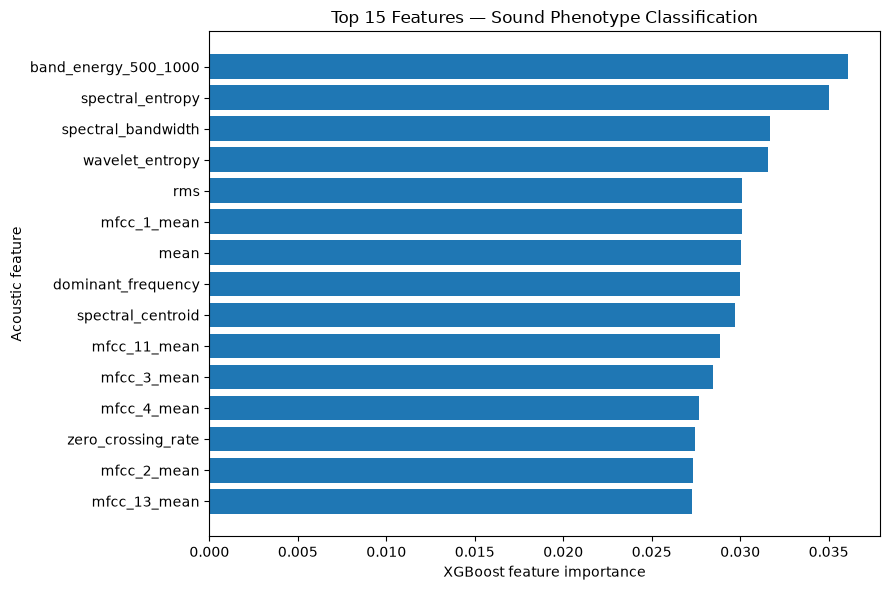

Saved: /Users/vs/Sem 5/Respiratory-Disease-Classification/models/sound_phenotype_cnn/xgboost/feature_importance.csv


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "feature": numeric_features,
    "importance": xgb_model.feature_importances_,
}).sort_values("importance", ascending=False)

importance_path = XGB_DIR / "feature_importance.csv"
importance_df.to_csv(importance_path, index=False)

print("Top 15 XGBoost features:")
display(importance_df.head(15))

plt.figure(figsize=(9, 6))
top_features = importance_df.head(15).sort_values("importance")
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("XGBoost feature importance")
plt.ylabel("Acoustic feature")
plt.title("Top 15 Features — Sound Phenotype Classification")
plt.tight_layout()
plt.show()

print("Saved:", importance_path)

In [10]:

from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path(
    "/Users/vs/Sem 5/Respiratory-Disease-Classification"
)

# Search for existing audit reports, manifests, and label mappings.
keywords = [
    "audit", "manifest", "label", "phenotype",
    "hf_lung", "fraiwan", "icbhi"
]

matches = []
for path in PROJECT_ROOT.rglob("*"):
    if not path.is_file():
        continue
    if any(k in path.name.lower() for k in keywords):
        if ".git" not in path.parts and "__pycache__" not in path.parts:
            matches.append(path)

print(f"Found {len(matches)} relevant files\n")
for path in matches[:150]:
    print(path.relative_to(PROJECT_ROOT))

print("\n--- Existing ICBHI phenotype manifests ---")
manifest_dir = (
    PROJECT_ROOT / "data/processed/deep_learning/cnn_baseline"
)
if manifest_dir.exists():
    for path in sorted(manifest_dir.glob("*")):
        if path.is_file():
            print(path.name, f"({path.stat().st_size:,} bytes)")

print("\n--- Existing phenotype feature table ---")
feature_path = (
    PROJECT_ROOT / "data/processed/features/"
    "respiratory_cycle_features.csv"
)
if feature_path.exists():
    df = pd.read_csv(feature_path, nrows=5)
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))
else:
    print("Feature table not found at expected path.")


Found 9849 relevant files

Notebooks 2/01_Fraiwan_Dataset_Audit.ipynb
Notebooks 2/01_Data_Audit.ipynb
Notebooks 2/01_HF_Lung_V1_Dataset_Audit.ipynb
notebooks/19_ICBHI_Sound_Phenotype_Classification.ipynb
reports/experiment_manifest.json
reports/final_artifacts/model_package_manifest.json
reports/final_artifacts/comparison_manifest.json
reports/final_artifacts/final_submission_zip_manifest.csv
reports/final_artifacts/artifact_file_manifest.csv
reports/final_artifacts/model_package_manifest.csv
notebooks/.ipynb_checkpoints/19_ICBHI_Sound_Phenotype_Classification-checkpoint.ipynb
data/raw/HF Lung V1/HF_Lung_V1-master.zip
data/raw/HF Lung V1/HF_Lung_V1-master/Dataset/test/steth_20190821_12_00_25_label.txt
data/raw/HF Lung V1/HF_Lung_V1-master/Dataset/test/steth_20190810_14_21_08_label.txt
data/raw/HF Lung V1/HF_Lung_V1-master/Dataset/test/steth_20191017_10_28_26_label.txt
data/raw/HF Lung V1/HF_Lung_V1-master/Dataset/test/trunc_2019-08-21-10-35-06-L1_1_label.txt
data/raw/HF Lung V1/HF_Lung